## Imports, paths, y funciones auxiliares

In [1]:
# Imports iniciales
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from collections import defaultdict
import matplotlib.patches as mpatches
from scipy import stats
import re
import seaborn as sns

In [2]:
# Lo pongo así para que no se rompa el path
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

RAW_DIR = ROOT / "data" / "raw"
# Acepta "Totalizador_Formateado" y "Totalizadores_Formateados"
archivos = sorted(RAW_DIR.glob("Totalizador*_Formateado*.csv"))
assert archivos, f"No hay CSV en {RAW_DIR}: correr primero src/procesado_raw.py"

SEP = " | "                   # separador "Hoja | columna" que pone el procesado
ERRORES_EXCEL = ["#VALUE!", "#DIV/0!", "#N/A", "#REF!", "#NAME?", "#NUM!", "#NULL!"]
LIMITE = 23 * 3600            # 23:00:00 en segundos desde medianoche

In [3]:
import json

ruta_columnas = ROOT / "data" / "processed" / "tratamientos_EDA.json"
# arranca vacío en cada corrida: refleja solo los pasos que corrió esta notebook
registro_columnas = {}  
ruta_columnas.write_text(json.dumps(registro_columnas), encoding="utf-8")

def registrar_borradas(paso, columnas):
    """Guarda en el JSON las columnas borradas en un paso (pisa el paso si ya existía).
    Si alguna columna borrada tenía tratamientos registrados, se los quita."""
    registro_columnas[paso] = sorted(columnas)
    tratamientos = registro_columnas.get("tratamientos", {})
    for col in columnas:
        tratamientos.pop(col, None)
    ruta_columnas.write_text(json.dumps(registro_columnas, ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"{paso}: {len(columnas)} columnas registradas en {ruta_columnas.name}")

def registrar_tratamiento(columnas, tratamiento):
    """Agrega el tratamiento a la lista de cada columna (clave 'tratamientos': {columna: [tratamientos en orden]}).
    Si la columna ya tiene ese tratamiento no lo repite (por si se vuelve a correr la celda)."""
    tratamientos = registro_columnas.setdefault("tratamientos", {})
    for col in columnas:
        lista = tratamientos.setdefault(col, [])
        if tratamiento not in lista:
            lista.append(tratamiento)
    ruta_columnas.write_text(json.dumps(registro_columnas, ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"{tratamiento}: {len(columnas)} columnas registradas en {ruta_columnas.name}")

In [4]:
def hoja_de(col):
    """'Consolidado EE | Frio (Kw)' -> 'Consolidado EE'. None para DIA, HORA"""
    return col.split(SEP, 1)[0] if SEP in col else None


def leer_formateado(ruta):
    # low_memory=False: con ~400 columnas de tipos mezclados pandas tipa por bloques
    df = pd.read_csv(ruta, low_memory=False, na_values=ERRORES_EXCEL,
                     dtype={"HORA": "string"})
    # El procesado escribe DIA como dd/mm/aaaa: sin format, pandas invierte día y mes
    df["DIA"] = pd.to_datetime(df["DIA"], format="%d/%m/%Y")
    return df

## Analisis inicial y Union
Primera parte del exploratorio, lo que quiero ver es como unir los 3 excels juntos y cuan mal están:

Los leo:

In [5]:
dfs = {}
for archivo in archivos:
    print("Leyendo", archivo.name)
    dfs[archivo.name] = leer_formateado(archivo)

for nombre, df in dfs.items():
    print(nombre, df.shape)

Leyendo Totalizador_Formateado 2020_2022.csv
Leyendo Totalizador_Formateado 2021_2023.csv
Leyendo Totalizador_Formateado 2022_2023.csv
Totalizador_Formateado 2020_2022.csv (15597, 343)
Totalizador_Formateado 2021_2023.csv (15318, 423)
Totalizador_Formateado 2022_2023.csv (12017, 430)


Parece que el primer excel tiene muchas menos columnas que los otros dos.

In [6]:
def a_segundos(horas):
    """Serie de horas en texto ('23:59:00') -> segundos desde las 00:00. NaN si no se entiende."""
    return pd.to_timedelta(horas, errors="coerce").dt.total_seconds()


def formato(seg):
    return f"{seg // 3600:02d}:{seg % 3600 // 60:02d}:{seg % 60:02d}"


def revisar_horas(df):
    """Horas posteriores a las 23:00:00 y valores de hora con formato raro."""
    horas = df["HORA"]
    segundos = a_segundos(horas)

    tarde = segundos[segundos > LIMITE]
    print("Horas > 23:00:00 (valor: cantidad de filas)")
    for seg, n in tarde.value_counts().sort_index().items():
        print(f"  {formato(int(seg))}: {n}")

    raros = horas[segundos.isna() & horas.notna()]
    if len(raros):
        print("Valores con formato no reconocido:")
        for valor, n in raros.astype(str).value_counts().items():
            print(f"  {valor!r}: {n}")

### Hoja Auxiliar

Al hacer una vista simple de los excels, vimos que hoja auxiliar no aporta nada, así que es lo primero que vamos a sacar.

In [7]:
# Auxiliar en los 3 archivos: % de nulos por columna, sobre todas las filas (no solo 23:59)
pct_aux = {}
for nombre, df in dfs.items():
    cols = [c for c in df.columns if hoja_de(c) == "Auxiliar"]
    pct_aux[nombre] = df[cols].isna().mean().mul(100).round(2)
    print(f"{nombre}: {len(cols)} columnas de Auxiliar | {len(df)} filas")

# Filas = columnas de Auxiliar, columnas = archivos.
# NaN en la tabla = esa columna no existe en ese archivo
tabla_aux = pd.DataFrame(pct_aux)
tabla_aux.index = tabla_aux.index.str.replace("Auxiliar | ", "", regex=False)
tabla_aux.columns = [c.replace("Totalizador_Formateado ", "").replace(".csv", "") for c in tabla_aux.columns]
tabla_aux

Totalizador_Formateado 2020_2022.csv: 32 columnas de Auxiliar | 15597 filas
Totalizador_Formateado 2021_2023.csv: 32 columnas de Auxiliar | 15318 filas
Totalizador_Formateado 2022_2023.csv: 33 columnas de Auxiliar | 12017 filas


,2020_2022,2021_2023,2022_2023
,0.15,0.01,100.0
.1,0.15,0.01,100.0
.10,100.00,100.00,100.0
.11,100.00,100.00,100.0
.12,100.00,100.00,100.0
.13,100.00,100.00,100.0
.14,100.00,100.00,100.0
.15,100.00,100.00,100.0
.16,100.00,100.00,100.0
.17,100.00,100.00,100.0


Está el porcentaje de nulos en cada columna. Existen algunas en las que se pueden encontrar valores, pero se ve que para el tercer excel es completamente nula, por lo tanto la sacamos.

In [8]:
# Saco todas las columnas de Auxiliar de los 3 archivos
for nombre, df in dfs.items():
    cols_aux = [c for c in df.columns if hoja_de(c) == "Auxiliar"]
    dfs[nombre] = df.drop(columns=cols_aux)
    print(f"{nombre}: saco {len(cols_aux)} columnas de Auxiliar -> {dfs[nombre].shape}")

Totalizador_Formateado 2020_2022.csv: saco 32 columnas de Auxiliar -> (15597, 311)
Totalizador_Formateado 2021_2023.csv: saco 32 columnas de Auxiliar -> (15318, 391)
Totalizador_Formateado 2022_2023.csv: saco 33 columnas de Auxiliar -> (12017, 397)


In [9]:
# Saco las filas que quedaron sin ningún dato (eran solo Auxiliar)
for nombre, df in dfs.items():
    cols = [c for c in df.columns if hoja_de(c) is not None] 
    vacias = df[cols].isna().all(axis=1)
    dfs[nombre] = df[~vacias].copy()
    print(f"{nombre}: saco {vacias.sum()} filas vacías -> {dfs[nombre].shape}")

Totalizador_Formateado 2020_2022.csv: saco 20 filas vacías -> (15577, 311)
Totalizador_Formateado 2021_2023.csv: saco 0 filas vacías -> (15318, 391)
Totalizador_Formateado 2022_2023.csv: saco 0 filas vacías -> (12017, 397)


### Análisis de días con más de 25 lecturas

In [10]:
# Cuántos días tienen N lecturas, por archivo: filas = N lecturas, columnas = archivo
dist_lecturas = pd.DataFrame({
    nombre.replace("Totalizador_Formateado ", "").replace(".csv", ""): df.groupby("DIA").size().value_counts()
    for nombre, df in dfs.items()
}).sort_index().fillna(0).astype(int)
dist_lecturas.index.name = "lecturas_por_dia"

dist_lecturas

,2020_2022,2021_2023,2022_2023
lecturas_por_dia,,,
8,1,0,1
9,0,1,0
16,0,1,1
17,0,0,1
20,0,0,1
23,2,3,1
24,5,3,0
25,594,585,459
26,2,1,4


Hay tres casos: 
- Tiene 25 valores, están bien (00:00 a 23:59).
- Tiene más de 25 valores. Si tiene 50/51, puede tenga dos días solapados. Idem. para 75 (no ocurre) o 100 (4 días juntos). 
- Tiene menos de 25 valores. Son días con pocas lecturas, que **no va a representar el consumo de esa jornada**.

Voy a arrancar por los días con más de 25 entradas. A los de 26 los voy a dejar como están por que seguramente sean valores duplicados y listo.
Para las columnas >26, lo que voy a hacer es si el 23:59 del bloque k tiene el mismo Frio que el del día DIA + k, el bloque es una copia y lo saco. Si es distinto, es otro día: va a DIA + k y las fechas que siguen se corren hasta el próximo día faltante.

In [11]:
MAX_FILAS = 26
FRIO = "Consolidado EE | Frio (Kw)"
INICIO_2359 = 23 * 3600 + 59 * 60

for nombre, df in dfs.items():
    conteo = df.groupby("DIA").size()
    es_pegado = df["DIA"].isin(conteo[conteo > MAX_FILAS].index)

    # 1. Bloques: corto cuando la hora vuelve para atrás y arranca en 00:xx (día nuevo).
    #    Las filas sueltas del final del día (partidas) no abren un bloque.
    seg = a_segundos(df["HORA"])
    corte = (seg.groupby(df["DIA"]).diff() < 0) & (seg < 3600) & es_pegado
    bloque = corte.groupby(df["DIA"]).cumsum()

    # 2. Desempate: Frio de las 23:59 de cada bloque contra el del día DIA + bloque
    tmp = pd.DataFrame({"DIA": df["DIA"], "bloque": bloque, "frio": df[FRIO]})
    cierre = (tmp[seg.between(INICIO_2359, INICIO_2359 + 59)]
              .groupby(["DIA", "bloque"])["frio"].first().reset_index())
    base = cierre[cierre["bloque"] == 0].set_index("DIA")["frio"]
    extra = cierre[cierre["bloque"] > 0].reset_index(drop=True)
    frio_siguiente = base.reindex(extra["DIA"] + pd.to_timedelta(extra["bloque"], unit="D")).reset_index(drop=True)
    copias = extra[(extra["frio"] - frio_siguiente).abs() < 1e-6]
    copias = set(zip(copias["DIA"], copias["bloque"]))

    claves = list(zip(df["DIA"], bloque))
    queda = [k not in copias for k in claves]
    df = df[queda].copy()
    claves = [k for k, q in zip(claves, queda) if q]

    # 3. Fechas: recorro los (DIA, bloque) en orden. Cada uno va a su DIA, o al día siguiente
    #    del anterior si ese ya está ocupado. Los días faltantes (31, 29-31/08) absorben el corrimiento.
    nueva_fecha, ultima = {}, None
    for dia, b in sorted(set(claves)):
        ultima = dia if ultima is None else max(dia, ultima + pd.Timedelta(days=1))
        nueva_fecha[(dia, b)] = ultima
    df["DIA"] = [nueva_fecha[k] for k in claves]
    dfs[nombre] = df


In [12]:
# Los archivos que arrancan el 01/07 no conocen el corrimiento que traía el archivo anterior:
# julio y agosto de su primer año se toman del archivo anterior
for i, nombre in enumerate(dfs):
    if i == 0:
        continue
    df = dfs[nombre]
    inicio = pd.Timestamp(year=df["DIA"].min().year, month=9, day=1)
    dfs[nombre] = df[df["DIA"] >= inicio].copy()

Despues de tratar a los días >26, me voy con los 21<. Directamente los voy a borrar, por que no acumulan datos. Dejo los de 23/24 por que un único valor faltante no influya tanto seguramente.


In [13]:
# Saco los días con menos de 20 lecturas
MIN_LECTURAS = 20
for nombre, df in dfs.items():
    lecturas = df.groupby("DIA")["DIA"].transform("size")
    dfs[nombre] = df[lecturas >= MIN_LECTURAS].copy()
    print(f"{nombre}: saco {(lecturas < MIN_LECTURAS).sum()} filas -> {dfs[nombre].shape}")

Totalizador_Formateado 2020_2022.csv: saco 8 filas -> (15569, 311)
Totalizador_Formateado 2021_2023.csv: saco 25 filas -> (13822, 391)
Totalizador_Formateado 2022_2023.csv: saco 41 filas -> (10501, 397)


### Filtrado Por Hora

Elegimos las 23:59 en vez de las 23:00 por que si no se estaría perdiendo una hora de producción (hay una hora de diferencia entre 23:00 y 00:00 que registra las :59).
Me ponga a ver como es el formato de las :59 

In [14]:
for nombre, df in dfs.items():
    print(f"\n=== {nombre} ===")
    revisar_horas(df)


=== Totalizador_Formateado 2020_2022.csv ===
Horas > 23:00:00 (valor: cantidad de filas)
  23:00:01: 10
  23:59:00: 614
  23:59:01: 7
  23:59:59: 1

=== Totalizador_Formateado 2021_2023.csv ===
Horas > 23:00:00 (valor: cantidad de filas)
  23:00:01: 5
  23:59:00: 548
  23:59:01: 4
  23:59:59: 1

=== Totalizador_Formateado 2022_2023.csv ===
Horas > 23:00:00 (valor: cantidad de filas)
  23:00:01: 4
  23:59:00: 416
  23:59:01: 3
  23:59:59: 1


In [15]:
def filtrar_2359(df):
    """Deja solo las filas con hora 23:59:xx (23:59:00, 23:59:01, 23:59:59)."""
    seg = a_segundos(df["HORA"].astype("string"))
    inicio = 23 * 3600 + 59 * 60          # 23:59:00
    fin = inicio + 59                     # 23:59:59
    return df[(seg >= inicio) & (seg <= fin)].copy()

Saco ahora todos los valores que no sean 
- 23:59:00
- 23:59:01
- 23:59:59

In [16]:
# Me quedo solo con la lectura de cierre (23:59:00, 23:59:01, 23:59:59)
for nombre, df in dfs.items():
    dfs[nombre] = filtrar_2359(df)
    print(f"{nombre}: {len(dfs[nombre])} filas 23:59 | {dfs[nombre]['DIA'].nunique()} días")

Totalizador_Formateado 2020_2022.csv: 622 filas 23:59 | 621 días
Totalizador_Formateado 2021_2023.csv: 553 filas 23:59 | 551 días
Totalizador_Formateado 2022_2023.csv: 420 filas 23:59 | 418 días


Ahora, con los datos juntados, uno todas las hojas de los archivos. Primero reviso que todos tengan las mismas hojas:

In [17]:
# Hojas de cada archivo y cuáles le faltan respecto del total
hojas_por_archivo = {n: {hoja_de(c) for c in df.columns} - {None} for n, df in dfs.items()}
todas = set.union(*hojas_por_archivo.values())
for n, h in hojas_por_archivo.items():
    print(f"{n}: {len(h)} hojas | faltan: {sorted(todas - h)}")


Totalizador_Formateado 2020_2022.csv: 14 hojas | faltan: ['Seguimiento Dia']
Totalizador_Formateado 2021_2023.csv: 15 hojas | faltan: []
Totalizador_Formateado 2022_2023.csv: 14 hojas | faltan: ['Seguimiento Dia']


Borro seguimiento día por que está en solo un excel:

In [18]:
# Seguimiento Dia está solo en 2021_2023: la saco de todos
HOJAS_DESCARTAR = ["Seguimiento Dia"]
for n, df in dfs.items():
    cols = [c for c in df.columns if hoja_de(c) in HOJAS_DESCARTAR]
    dfs[n] = df.drop(columns=cols)
    print(f"{n}: saco {len(cols)} columnas de {HOJAS_DESCARTAR}")

Totalizador_Formateado 2020_2022.csv: saco 0 columnas de ['Seguimiento Dia']
Totalizador_Formateado 2021_2023.csv: saco 3 columnas de ['Seguimiento Dia']
Totalizador_Formateado 2022_2023.csv: saco 0 columnas de ['Seguimiento Dia']


### Análisis de tipo de dato

In [19]:
# Tipos de dato por archivo: cuántas columnas hay de cada tipo
tipos = pd.DataFrame({
    nombre.replace("Totalizador_Formateado ", "").replace(".csv", ""): df.dtypes.astype(str).value_counts()
    for nombre, df in dfs.items()
}).fillna(0).astype(int)
print(tipos, "\n")

# Columnas que no son numéricas ni fecha, por archivo
for nombre, df in dfs.items():
    print(f"{nombre}: {df.select_dtypes(exclude=['number', 'datetime']).columns.tolist()}")

                2020_2022  2021_2023  2022_2023
datetime64[us]          1          1          1
float64               302        385        394
str                     7          1          1
string                  1          1          1 

Totalizador_Formateado 2020_2022.csv: ['HORA', 'Totalizadores Produccion | Nivel Silo Bagazo Norte (1)', 'Totalizadores Energia | KW Trafo 8', 'Totalizadores Efluentes | Totalizador Bba P1', 'Totalizadores Efluentes | Totalizador Bba P2', 'Totalizadores Efluentes | Totalizador Bba P4', 'Totalizadores Efluentes | Totalizador Bba Envasado', 'Totalizadores Efluentes | Totalizador Bba P51']
Totalizador_Formateado 2021_2023.csv: ['HORA', 'Totalizadores Energia | KW Trafo 8']
Totalizador_Formateado 2022_2023.csv: ['HORA', 'Consolidado KPI | Unnamed: 124']


In [20]:
def a_float(serie):
    if pd.api.types.is_numeric_dtype(serie):
        return serie.astype("float64")
    txt = serie.astype("string").str.strip()
    # punto de miles: hay 2 o más puntos, o hay punto y coma a la vez
    miles = (txt.str.count(r"\.").ge(2) | (txt.str.contains(".", regex=False) & txt.str.contains(",", regex=False))).fillna(False)
    txt = txt.mask(miles, txt.str.replace(".", "", regex=False))
    return pd.to_numeric(txt.str.replace(",", ".", regex=False), errors="coerce").astype("float64")

NO_CONVERTIR = ["DIA", "HORA"]
for nombre, df in dfs.items():
    cols = df.columns.drop(NO_CONVERTIR, errors="ignore")
    df[cols] = df[cols].apply(a_float)
    dfs[nombre] = df
    print(f"{nombre}: {df.dtypes.astype(str).value_counts().to_dict()}")

Totalizador_Formateado 2020_2022.csv: {'float64': 309, 'datetime64[us]': 1, 'string': 1}
Totalizador_Formateado 2021_2023.csv: {'float64': 386, 'datetime64[us]': 1, 'string': 1}
Totalizador_Formateado 2022_2023.csv: {'float64': 395, 'datetime64[us]': 1, 'string': 1}


### Union de los datos

In [21]:
# Uno los 3 archivos (ya filtrados a 23:59)
partes = []
for nombre, df in dfs.items():
    f = df.copy()
    f.insert(0, "ARCHIVO", nombre.replace("Totalizador_Formateado ", "").replace(".csv", ""))
    partes.append(f)

df_total = pd.concat(partes, ignore_index=True).sort_values(["DIA", "HORA"], kind="stable").reset_index(drop=True)
print(df_total.shape, df_total["DIA"].min().date(), "->", df_total["DIA"].max().date())

(1595, 412) 2020-07-01 -> 2023-10-27


# Analisis del DF completo

Para ver la cantidad de días únicos: 

In [22]:
# Días únicos en el df unido, y cuántos aparecen repetidos
por_dia = df_total.groupby("DIA").agg(filas=("ARCHIVO", "size"), archivos=("ARCHIVO", "nunique"))
print("Días únicos:", len(por_dia))
print("Días con más de una fila:", (por_dia["filas"] > 1).sum())
print("Días presentes en más de un archivo:", (por_dia["archivos"] > 1).sum())
print("Días repetidos dentro de un mismo archivo:", df_total.groupby(["ARCHIVO", "DIA"]).size().gt(1).sum())

Días únicos: 1205
Días con más de una fila: 388
Días presentes en más de un archivo: 385
Días repetidos dentro de un mismo archivo: 5


In [23]:
df_total = df_total.drop(columns=["HORA", "ARCHIVO"])

## Tratamiento de los unnameds 

Al ver el dataset, encontramos muchas columnas llamadas unnamed (numero). Puede que haya alguna que tenga valores de verdad, y otras que simplemente son errores. Para descartar los errores, vamos a hacer un df aparte con los unnameds y analizar el porcentaje de nulos:

In [24]:
# Columnas unnamed (vienen como "Hoja | Unnamed: N")
cols_unnamed = [c for c in df_total.columns if "Unnamed" in c]

unnamed = pd.DataFrame({
    "hoja": [hoja_de(c) for c in cols_unnamed],
    "nulos": df_total[cols_unnamed].isna().sum(),
}, index=cols_unnamed)

unnamed["pct_nulos"] = (unnamed["nulos"] / len(df_total) * 100).round(2)
unnamed = unnamed.sort_values("pct_nulos")

print(f"{len(unnamed)} columnas unnamed")
unnamed

24 columnas unnamed


,hoja,nulos,pct_nulos
Consolidado Produccion | Unnamed: 15,Consolidado Produccion,1552,97.30
Consolidado Produccion | Unnamed: 16,Consolidado Produccion,1552,97.30
Consolidado Produccion | Unnamed: 17,Consolidado Produccion,1552,97.30
Consolidado Produccion | Unnamed: 18,Consolidado Produccion,1552,97.30
Totalizadores Energia | Unnamed: 53,Totalizadores Energia,1564,98.06
Totalizadores Energia | Unnamed: 54,Totalizadores Energia,1594,99.94
Totalizadores Energia | Unnamed: 56,Totalizadores Energia,1594,99.94
Totalizadores Energia | Unnamed: 55,Totalizadores Energia,1594,99.94
Totalizadores Energia | Unnamed: 57,Totalizadores Energia,1594,99.94
Totalizadores Energia | Unnamed: 58,Totalizadores Energia,1594,99.94


In [25]:
df_recortado = df_total.drop(columns=unnamed.index)
print(f"Saco {len(unnamed)} columnas unnamed -> {df_recortado.shape}")

Saco 24 columnas unnamed -> (1595, 386)


## Tratado de duplicados y regla de desempate

Vamos a tomar como criterio de desempate: 
- Nos quedamos con la fila con mayor cantidad de valores nulos, y en caso que la fila descartada tenga algún valor real que para la fila guardada es nula, se va a rellenar. 

In [26]:
# Días que aparecen en más de una fila (se cuenta la clave DIA, no las filas)
df_dup = df_recortado.copy()
dias_repetidos = df_dup.loc[df_dup["DIA"].duplicated(keep=False), "DIA"].drop_duplicates()

print("Total de días repetidos:", len(dias_repetidos), "\n")
#print(df_dup[df_dup["DIA"].duplicated() == True])


Total de días repetidos: 388 



In [27]:
cols_datos = df_dup.columns.drop("DIA")

# Cantidad de nulos de cada fila; _orden guarda el orden original para el desempate
df_dup["_nulos"] = df_dup[cols_datos].isna().sum(axis=1)        
df_dup["_orden"] = range(len(df_dup))   

# Dentro de cada día: primero la fila con menos nulos; si empatan, la que venía primero
ordenado = df_dup.sort_values(["DIA", "_nulos", "_orden"])

print(ordenado[["DIA", "_nulos", "_orden"]].head(10))
# first() toma, por columna, el primer valor no nulo del grupo:
# la fila base conserva sus valores y sus huecos se rellenan con las siguientes
df_unido = ordenado.groupby("DIA", sort=True)[list(cols_datos)].first().reset_index()

assert df_unido["DIA"].is_unique
assert len(df_unido) == df_dup["DIA"].nunique()

         DIA  _nulos  _orden
0 2020-07-01      91       0
1 2020-07-02      91       1
2 2020-07-03      91       2
3 2020-07-04      91       3
4 2020-07-05      91       4
5 2020-07-06      91       5
6 2020-07-07      91       6
7 2020-07-08      91       7
8 2020-07-09      91       8
9 2020-07-10      91       9


Como tengo que guardar las columnas borradas así el pipeline toma las correctas, creo el json y una función para registrar.

## Valores Nulos

In [28]:
def matriz_nulidad(datos, umbral=None, titulo="Matriz de nulidad por fecha", col_fecha="DIA"):
    """Grafica los nulos por día (filas, en orden cronológico) y por columna (de más a menos nulos).

    Negro = nulo. Si se pasa `umbral` (en %), marca las columnas que lo superan.
    Las líneas azules indican desde qué fecha aporta cada archivo (después del recorte de jul-ago).
    """
    n_nulos = datos.isna().sum()
    cols_con_nulos = n_nulos[n_nulos > 0].sort_values(ascending=False, kind="stable").index
    if len(cols_con_nulos) == 0:
        print("No hay columnas con nulos.")
        return

    matriz = datos.sort_values(col_fecha).set_index(col_fecha)[cols_con_nulos].isna()
    fechas = matriz.index

    fig, ax = plt.subplots(figsize=(14, 9))
    ax.imshow(matriz.to_numpy(), aspect="auto", cmap="Greys", interpolation="nearest")

    # Eje Y: fechas cada trimestre
    marcas = np.where(fechas.is_month_start & fechas.month.isin([1, 4, 7, 10]))[0]
    ax.set_yticks(marcas)
    ax.set_yticklabels(fechas[marcas].strftime("%Y-%m"))
    ax.set_ylabel("Día (orden cronológico)")

    # Eje X: demasiadas columnas para rotularlas una por una
    ax.set_xticks([])
    ax.set_xlabel(f"{len(cols_con_nulos)} columnas con nulos, de más a menos nulos")

    # Columnas que superan el umbral (quedan a la izquierda por el orden)
    if umbral is not None:
        pct = n_nulos[cols_con_nulos] / len(datos) * 100
        n_sobre_umbral = (pct > umbral).sum()
        if n_sobre_umbral > 0:
            ax.axvline(n_sobre_umbral - 0.5, color="red", linewidth=1.5)
            ax.text(n_sobre_umbral, 5, f" ← > {umbral} % de nulos ({n_sobre_umbral})",
                    color="red", va="top", fontsize=9)

    # Desde dónde aporta cada archivo
    for fecha, archivo in [("2021-09-01", "2021_2023"), ("2022-09-01", "2022_2023")]:
        if pd.Timestamp(fecha) in fechas:
            y = fechas.get_loc(pd.Timestamp(fecha))
            ax.axhline(y, color="tab:blue", linestyle="--", linewidth=1)
            ax.text(len(cols_con_nulos) - 1, y, f"entra {archivo} ({fecha})",
                    color="tab:blue", ha="right", va="bottom", fontsize=9)

    ax.set_title(titulo)
    plt.tight_layout()
    plt.show()

En primer lugar vamos a ver la cantidad de nulos por %, y ver cuantos son y cuanto efecto va a tener borrarlos. Como valor inicial de muestra tomamos 45% (más tarde lo cambiamos a 36, justifico más abajo) como el umbral de nulos máximo para borrarlo.

In [29]:
UMBRAL_NULOS = 36
protegidas = ["DIA", "target", "Consolidado EE | Frio (Kw)"]

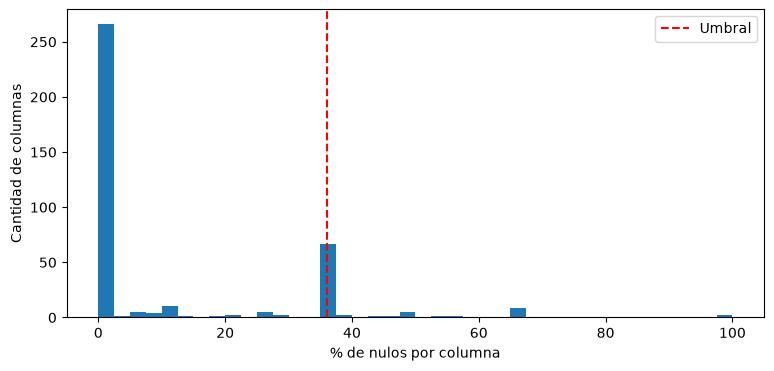

In [30]:
pct_nulos = df_unido.isna().mean().mul(100).sort_values(ascending=False)

# Cuántas columnas caen en cada rango de % de nulos
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(pct_nulos, bins=40)
ax.set_xlabel("% de nulos por columna")
ax.set_ylabel("Cantidad de columnas")

# Umbral Nulos
ax.axvline(UMBRAL_NULOS, color="red", linestyle="--", label="Umbral")
ax.legend()
plt.show()

Hay un pico de nulos cerca del 40. Los voy a buscar y voy a ver que está pasando.

In [31]:
n_nulos = df_unido.isna().sum()
en_rango = n_nulos[(pct_nulos > 25) & (pct_nulos <= 45)]
conteo = en_rango.value_counts()
display(conteo.head(5).rename_axis("cantidad de nulos").to_frame("columnas"))

n_pico = conteo.index[0]
cols_pico = en_rango[en_rango == n_pico].index
print(f"Pico: {n_pico} nulos ({n_pico / len(df_unido) * 100:.2f} %) en {len(cols_pico)} de {len(en_rango)} columnas del rango 25-45 %")

nulos_pico = df_unido[cols_pico].isna()
detalle = pd.DataFrame({
    "primer dato": df_unido.loc[nulos_pico.eq(False).idxmax(), "DIA"].to_numpy(),
    "último nulo": df_unido.loc[nulos_pico[::-1].idxmax(), "DIA"].to_numpy(),
}, index=cols_pico)


,columnas
cantidad de nulos,
423,67
326,3
308,2
348,2
461,1


Pico: 423 nulos (35.10 %) en 67 de 77 columnas del rango 25-45 %


In [32]:
for (primero, ultimo), grupo in detalle.groupby(["primer dato", "último nulo"]):
    print(f"\nPrimer dato: {primero.date()} | último nulo: {ultimo.date()} -> {len(grupo)} columnas")
    for col in sorted(grupo.index):
        print(f"  - {col}")


Primer dato: 2021-09-01 | último nulo: 2021-08-31 -> 67 columnas
  - Consolidado Agua | Agua CO2
  - Consolidado Agua | Agua Calderas
  - Consolidado Agua | Agua Cond Evaporativos
  - Consolidado Agua | Agua Efluentes
  - Consolidado Agua | Agua Lavadora L3
  - Consolidado Agua | Agua Paste L3
  - Consolidado GasVapor | Medicion Gas Planta (M3)
  - Consolidado GasVapor | Tot Vap Lav L3 / Hora
  - Consolidado GasVapor | Tot Vap Paste L3 / Hora
  - Consolidado GasVapor | Vapor_L5 (KG)
  - Consolidado KPI | Agua Lavadora L3 / Hl
  - Consolidado KPI | Agua Paste L3 / Hl
  - Consolidado KPI | Meta Agua Bodega
  - Consolidado KPI | Meta Agua Cocina
  - Consolidado KPI | Meta Agua Elab
  - Consolidado KPI | Meta Agua Envas
  - Consolidado KPI | Meta Agua Linea 2
  - Consolidado KPI | Meta Agua Linea 3
  - Consolidado KPI | Meta Agua Linea 4
  - Consolidado KPI | Meta Agua Linea 5
  - Consolidado KPI | Meta Agua Planta
  - Consolidado KPI | Meta Agua Planta de Agua
  - Consolidado KPI | Meta 

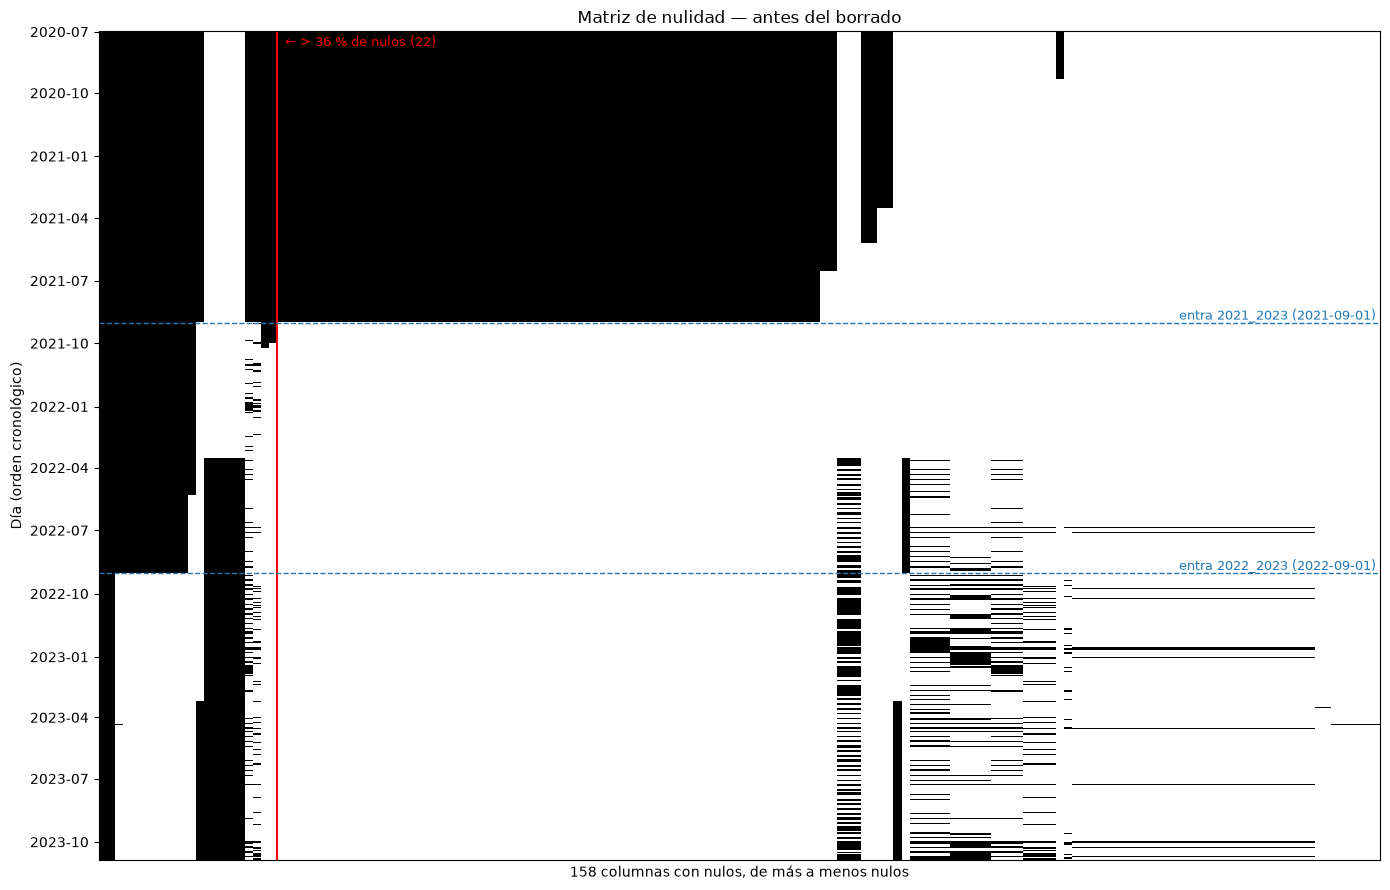

In [33]:
matriz_nulidad(df_unido, umbral=UMBRAL_NULOS, titulo="Matriz de nulidad — antes del borrado")

### Borrado de nulos por umbral y nueva matriz

Viendo la matriz de nulidad, hay un año entero de datos faltantes. Voy a borrar los otros primero y ver cual es el problema.

In [34]:
a_borrar = pct_nulos[(pct_nulos > UMBRAL_NULOS) & ~pct_nulos.index.isin(protegidas)].index
df_nulos = df_unido.drop(columns=a_borrar)

print(f"Columnas borradas (> {UMBRAL_NULOS} % de nulos): {len(a_borrar)}")
print(f"Columnas: {df_unido.shape[1]} -> {df_nulos.shape[1]}")

# Guardo en el .json
registrar_borradas(f"nulos_mayor_{UMBRAL_NULOS}", a_borrar)

Columnas borradas (> 36 % de nulos): 22
Columnas: 386 -> 364
nulos_mayor_36: 22 columnas registradas en tratamientos_EDA.json


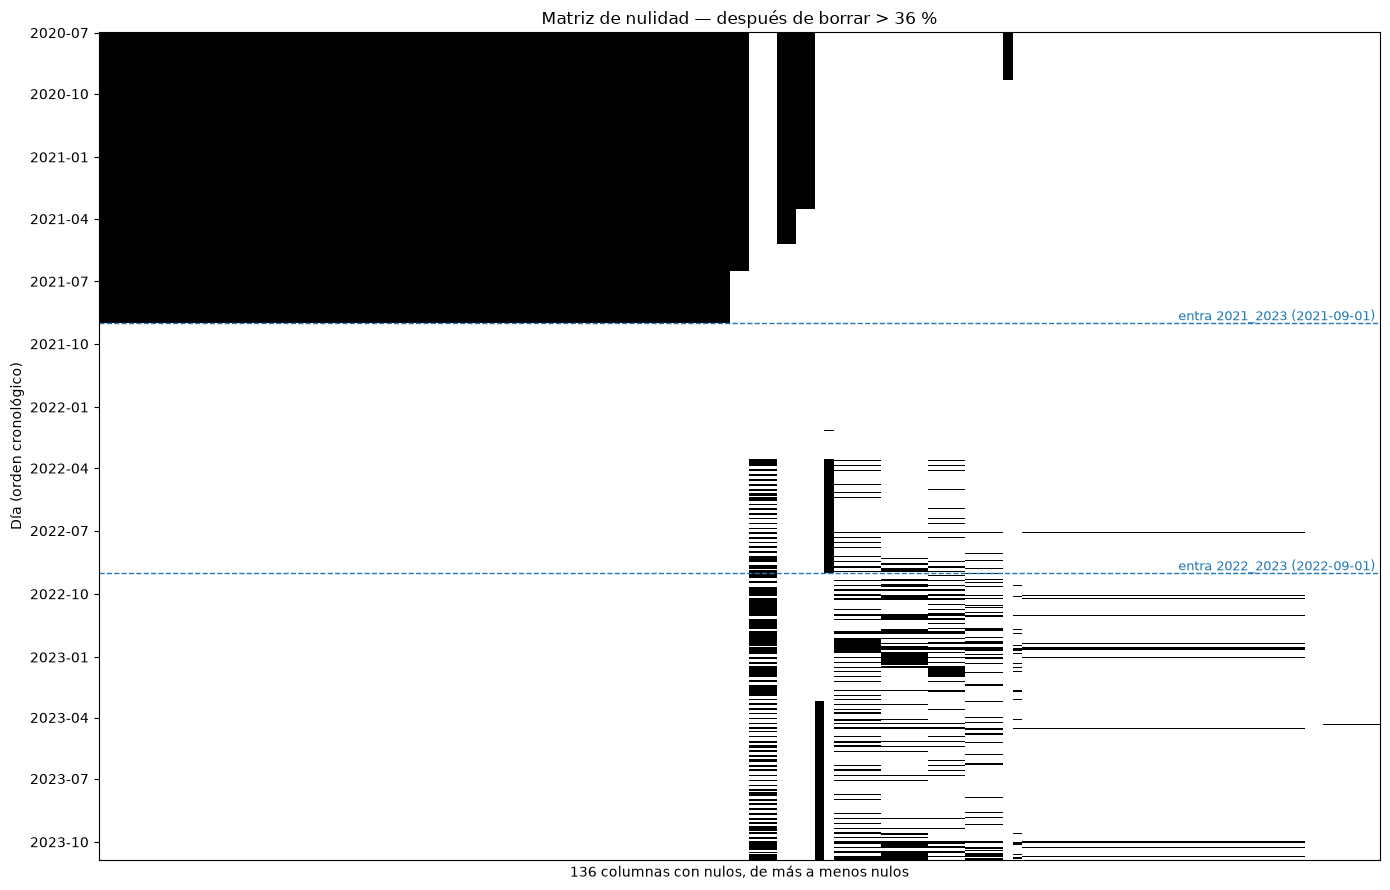

In [35]:
matriz_nulidad(df_nulos, umbral=UMBRAL_NULOS, titulo=f"Matriz de nulidad — después de borrar > {UMBRAL_NULOS} %")

### Metas
Ya teníamos la sospecha que metas no estaban en los datos mas viejos, lo confirmamos:

In [36]:
cols_meta = [c for c in df_unido.columns if c.split(" | ", 1)[-1].strip().lower().startswith("meta")]
pct_meta = df_unido[cols_meta].isna().mean().mul(100).sort_values(ascending=False)

borradas_meta = [c for c in cols_meta if c in a_borrar]
print(f"Columnas de metas: {len(cols_meta)} | borradas por > {UMBRAL_NULOS} % de nulos: {len(borradas_meta)} "
      f"| quedan en df_nulos: {len(cols_meta) - len(borradas_meta)}\n")

for col, pct in pct_meta.items():
    estado = "  (BORRADA)" if col in a_borrar else ""
    print(f"{pct:6.2f} %  {col}{estado}")


Columnas de metas: 51 | borradas por > 36 % de nulos: 0 | quedan en df_nulos: 51

 35.10 %  Consolidado KPI | Meta EE Planta
 35.10 %  Consolidado KPI | Meta Agua Planta
 35.10 %  Consolidado KPI | Meta ET Planta
 35.10 %  Consolidado KPI | Meta Aire Planta
 35.10 %  Consolidado KPI | Meta Agua Elab
 35.10 %  Consolidado KPI | Meta Agua Bodega
 35.10 %  Consolidado KPI | Meta Agua Cocina
 35.10 %  Consolidado KPI | Meta Agua Envas
 35.10 %  Consolidado KPI | Meta Agua Linea 2
 35.10 %  Consolidado KPI | Meta Agua Linea 3
 35.10 %  Consolidado KPI | Meta Agua Linea 4
 35.10 %  Consolidado KPI | Meta Agua Linea 5
 35.10 %  Consolidado KPI | Meta Agua Servicios
 35.10 %  Consolidado KPI | Meta Agua Planta de Agua
 35.10 %  Consolidado KPI | Meta Produccion Agua
 35.10 %  Consolidado KPI | Meta EE Elaboracion
 35.10 %  Consolidado KPI | Meta EE Bodega
 35.10 %  Consolidado KPI | Meta EE Cocina
 35.10 %  Consolidado KPI | Meta EE Envasado
 35.10 %  Consolidado KPI | Meta EE Linea 2
 35.10 %

Esto seguramente ocurre por que en años pasados, no se tomaban metas de consumo. Como más abajo en feature engineering habla de eficiencia energética, seguramente sea importante. Quiero ver primero como es la estructura de meta vs consumo real en los años que si existe.

In [37]:
def ver_dias(datos, columnas, desde, dias=10, col_fecha="DIA"):
    """Muestra `dias` días seguidos desde `desde` para las `columnas` pedidas.
    Días como columnas y variables como filas. Avisa si alguna columna no está en el df."""
    faltan = [c for c in columnas if c not in datos.columns]
    if faltan:
        print("No están en el df:", faltan)
    cols = [c for c in columnas if c in datos.columns]

    inicio = pd.Timestamp(desde)
    fin = inicio + pd.Timedelta(days=dias - 1)
    ventana = datos.loc[datos[col_fecha].between(inicio, fin), [col_fecha, *cols]].set_index(col_fecha)
    ventana.index = ventana.index.strftime("%d/%m/%y")
    return ventana.T.round(3)

In [38]:
desde = "2022-02-24"

display(ver_dias(df_nulos, ["Consolidado KPI | Meta EE Planta",
                            "Consolidado KPI | EE Planta / Hl",
                            "Consolidado EE | Planta (Kw)"], desde))

DIA,24/02/22,25/02/22,26/02/22,27/02/22,28/02/22,01/03/22,02/03/22,03/03/22,04/03/22
Consolidado KPI | Meta EE Planta,6.500,6.500,6.50,6.500,6.500,6.500,6.500,6.500,6.300
Consolidado KPI | EE Planta / Hl,7.992,8.978,5.95,7.155,5.733,5.782,5.778,8.112,6.111
Consolidado EE | Planta (Kw),58005.580,62806.170,67257.80,63439.130,53616.450,69975.380,69911.330,61830.170,68704.870


Metas está siempre en Hl. Lo que voy a hacer más tarde en feature engineering es crear la eficiencia energética consumo/meta; en el caso que sea perfecto significa que es 1. 
Por ahora, para poder seguir con la limpieza, voy a imputarlo con 1; **pero para el pipeline cuando tenga mi división test/train, voy a imputarlo con la media de la eficiencia**.

Columnas de metas: 51 | valores imputados con 1: 21573
Días sin meta: 423 (2020-07-01 -> 2021-08-31)


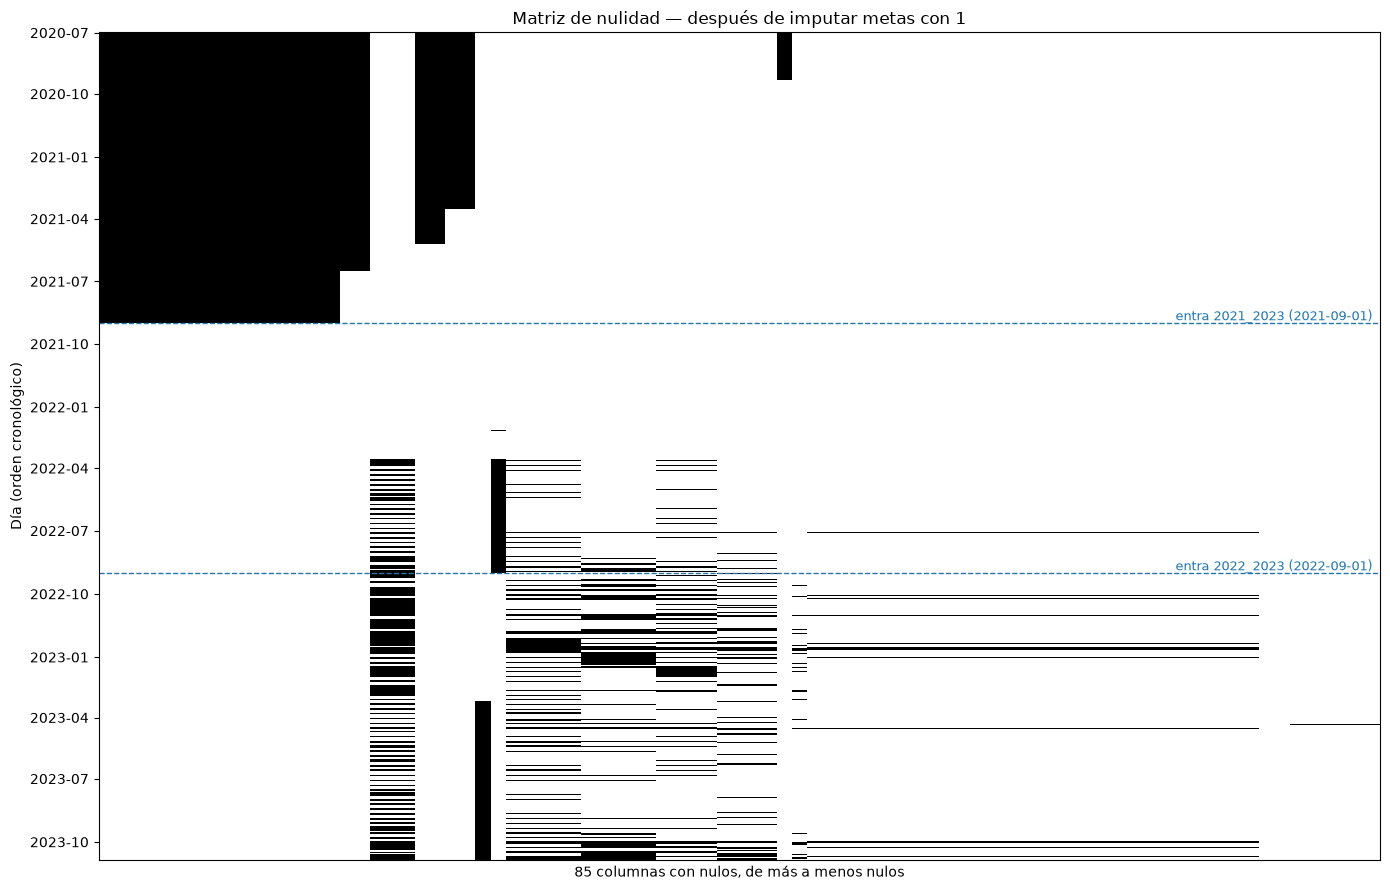

media_train_si_no_hay_meta: 51 columnas registradas en tratamientos_EDA.json


In [39]:
metas = [c for c in df_nulos.columns if c.split(" | ", 1)[-1].strip().lower().startswith("meta")]

df_metas = df_nulos.copy()

# Indicador: días sin ninguna meta (antes de rellenar, para no perder cuáles faltaban)
df_metas["no_hay_meta"] = df_metas[metas].isna().all(axis=1).astype(int)

# Relleno provisorio con 1 (se reemplaza por la media de train después del split)
n_imputados = df_metas[metas].isna().sum().sum()
df_metas[metas] = df_metas[metas].fillna(1)

sin_meta = df_metas.loc[df_metas["no_hay_meta"] == 1, "DIA"]
print(f"Columnas de metas: {len(metas)} | valores imputados con 1: {n_imputados}")
print(f"Días sin meta: {len(sin_meta)} ({sin_meta.min().date()} -> {sin_meta.max().date()})")

matriz_nulidad(df_metas, titulo="Matriz de nulidad — después de imputar metas con 1")
registrar_tratamiento(metas, "media_train_si_no_hay_meta")

In [40]:
nulos = df_metas.isna()
cols_nulos = nulos.sum()[lambda s: s > 0].sort_values(ascending=False, kind="stable").index
nulos = nulos[cols_nulos]
fechas = df_metas["DIA"]

tabla_nulos = pd.DataFrame({
    "n nulos": nulos.sum(),
    "% nulos": nulos.mean().mul(100).round(2),
    "tramos": (nulos & ~nulos.shift(fill_value=False)).sum(),   # bloques seguidos de nulos
})

print(f"Columnas con nulos: {len(tabla_nulos)} de {df_metas.shape[1]}")
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(tabla_nulos)

Columnas con nulos: 85 de 365


,n nulos,% nulos,tramos
Consolidado KPI | Agua Lavadora L3 / Hl,423,35.10,1
Consolidado KPI | Agua Paste L3 / Hl,423,35.10,1
Consolidado Produccion | Hl de Mosto Copia,423,35.10,1
Consolidado Agua | Agua Paste L3,423,35.10,1
Consolidado Agua | Agua Lavadora L3,423,35.10,1
Consolidado Agua | Agua Cond Evaporativos,423,35.10,1
Consolidado Agua | Agua Calderas,423,35.10,1
Consolidado Agua | Agua Efluentes,423,35.10,1
Consolidado Agua | Agua CO2,423,35.10,1
Consolidado GasVapor | Vapor_L5 (KG),423,35.10,1


Me freno en la parte debajo de Totalizadores Glicol - Tot Traziego. Todos esos valores vienen de KPI (menos los ultimos, que son un único nulo).
Son pocos y ra el porcentaje del dataset, así que directamente los voy a imputar por por la media pero usando el promedio de los días anteriores.

In [41]:
def imputar_promedio_anteriores(datos, columnas, n=2, col_fecha="DIA", invalidar_negativos=False):
    """Rellena cada nulo con el promedio de los `n` valores válidos anteriores.

    Solo mira hacia atrás: no usa información del futuro
    y se comporta igual en train que en predict.py.
    Si hay varios nulos seguidos, todos reciben el promedio de los n válidos previos al hueco.
    Si no hay ningún valor válido antes (inicio de la serie), usa el siguiente válido.
    Si `invalidar_negativos=True`, los negativos se tratan como nulos.
    """
    df = datos.sort_values(col_fecha).copy()
    if invalidar_negativos:
        df[columnas] = df[columnas].mask(df[columnas] < 0)
    for col in columnas:
        s = df[col]
        media_previa = s.dropna().rolling(n, min_periods=1).mean().reindex(s.index).ffill()
        df[col] = s.fillna(media_previa).fillna(s.bfill())
    return df

Columnas imputadas: 38 | valores imputados: 668
Nulos que quedan en esas columnas: 0
promedio_anteriores: 38 columnas registradas en tratamientos_EDA.json


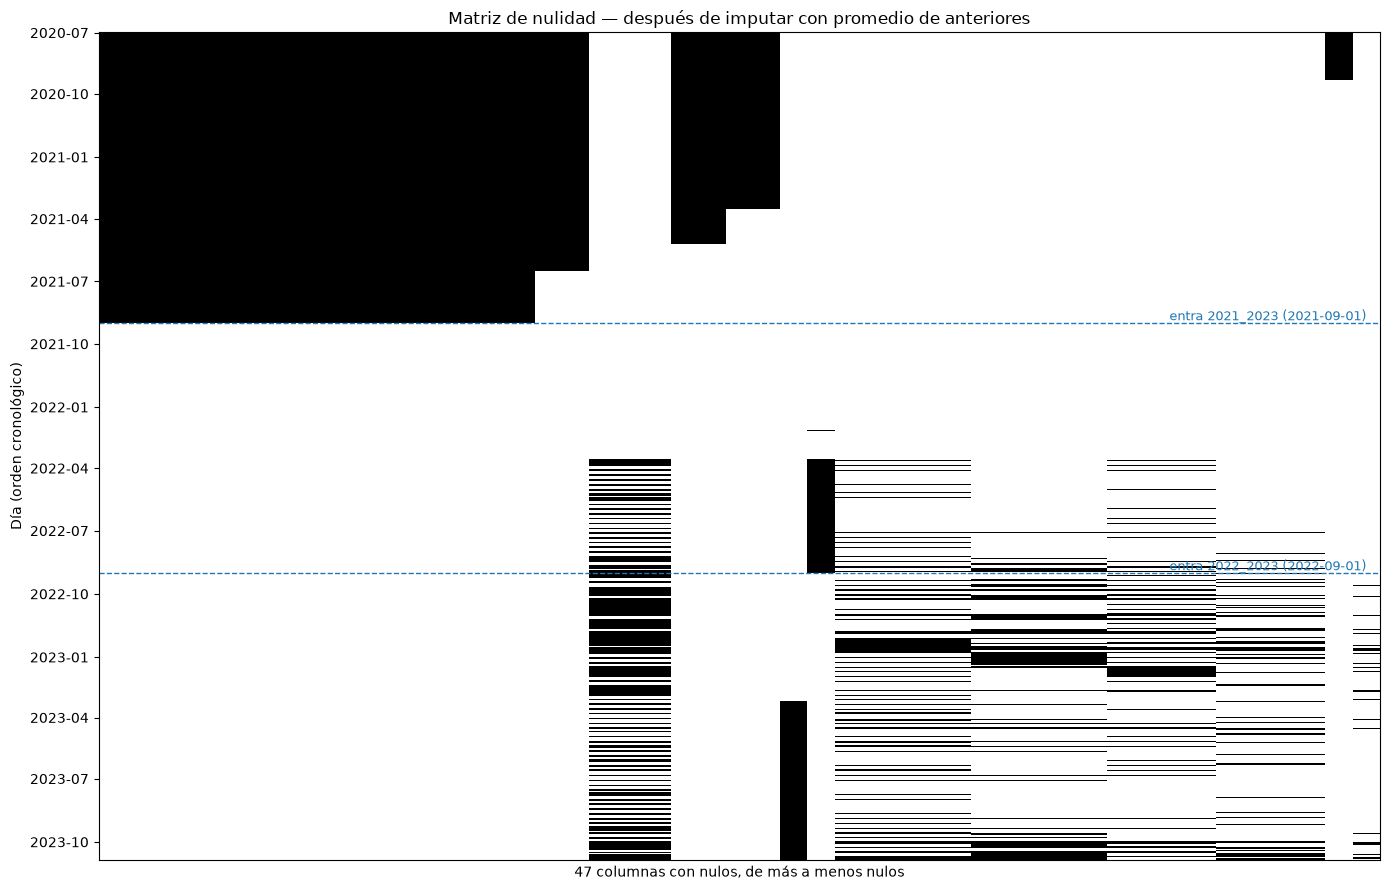

In [42]:
pos_ee = tabla_nulos.index.get_loc("Consolidado KPI | EE Planta / Hl")
cols_vecinos = list(tabla_nulos.index[pos_ee:])

df_imp = imputar_promedio_anteriores(df_metas, cols_vecinos)

print(f"Columnas imputadas: {len(cols_vecinos)} | valores imputados: {df_metas[cols_vecinos].isna().sum().sum()}")
print(f"Nulos que quedan en esas columnas: {df_imp[cols_vecinos].isna().sum().sum()}")

registrar_tratamiento(cols_vecinos, "promedio_anteriores")

matriz_nulidad(df_imp, titulo="Matriz de nulidad — después de imputar con promedio de anteriores")

Columnas con uno o dos tramos de nulos: 25

 35.10 %  (1 tramo)  Consolidado Agua | Agua CO2
 35.10 %  (1 tramo)  Consolidado Agua | Agua Efluentes
 35.10 %  (1 tramo)  Consolidado Agua | Agua Calderas
 35.10 %  (1 tramo)  Consolidado Agua | Agua Cond Evaporativos
 35.10 %  (1 tramo)  Consolidado Agua | Agua Lavadora L3
 35.10 %  (1 tramo)  Consolidado Agua | Agua Paste L3
 35.10 %  (1 tramo)  Consolidado Produccion | Hl de Mosto Copia
 35.10 %  (1 tramo)  Consolidado KPI | Agua Paste L3 / Hl
 35.10 %  (1 tramo)  Consolidado KPI | Agua Lavadora L3 / Hl
 35.10 %  (1 tramo)  Consolidado GasVapor | Medicion Gas Planta (M3)
 35.10 %  (1 tramo)  Consolidado GasVapor | Vapor_L5 (KG)
 35.10 %  (1 tramo)  Consolidado GasVapor | Tot Vap Paste L3 / Hora
 35.10 %  (1 tramo)  Consolidado GasVapor | Tot Vap Lav L3 / Hora
 35.10 %  (1 tramo)  Totalizadores Glicol | Tot A40/240/50/60/Centec/Filtro
 35.10 %  (1 tramo)  Totalizadores Gas y Vapor | Vapor_L5 (KG)
 35.10 %  (1 tramo)  Totalizadores Glicol

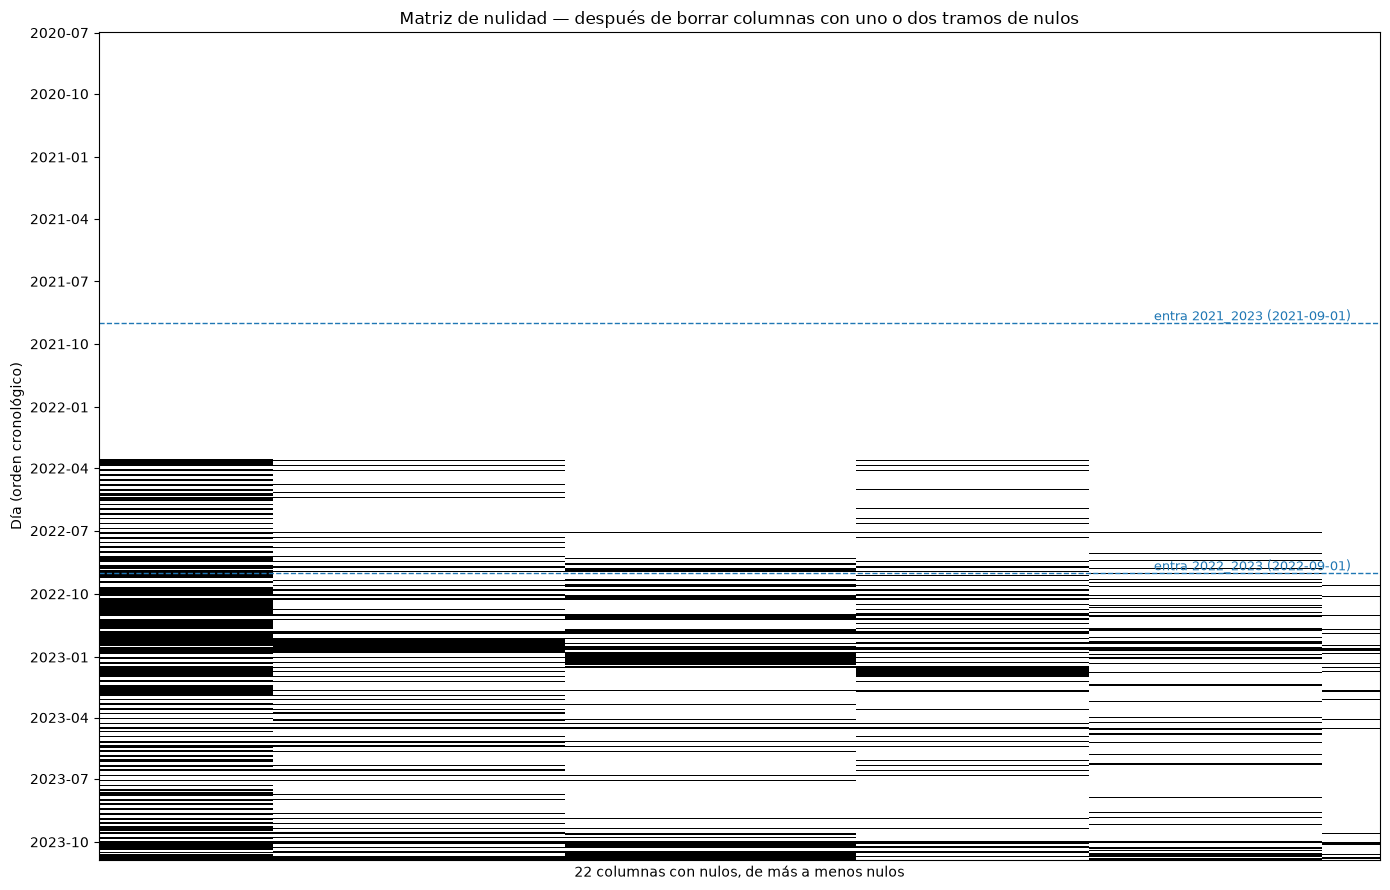

In [43]:
nulos_imp = df_imp.isna()
tramos = (nulos_imp & ~nulos_imp.shift(fill_value=False)).sum()
pocos_tramos = tramos[tramos.between(1, 2) & ~tramos.index.isin(protegidas)].index

pct_pocos = nulos_imp[pocos_tramos].mean().mul(100).sort_values(ascending=False)
print(f"Columnas con uno o dos tramos de nulos: {len(pocos_tramos)}\n")
for col, pct in pct_pocos.items():
    print(f"{pct:6.2f} %  ({tramos[col]} tramo{'s' if tramos[col] > 1 else ''})  {col}")

df_tramo = df_imp.drop(columns=pocos_tramos)
print(f"\nColumnas: {df_imp.shape[1]} -> {df_tramo.shape[1]}")

registrar_borradas("nulos_uno_o_dos_tramos", pocos_tramos)

matriz_nulidad(df_tramo, titulo="Matriz de nulidad — después de borrar columnas con uno o dos tramos de nulos")

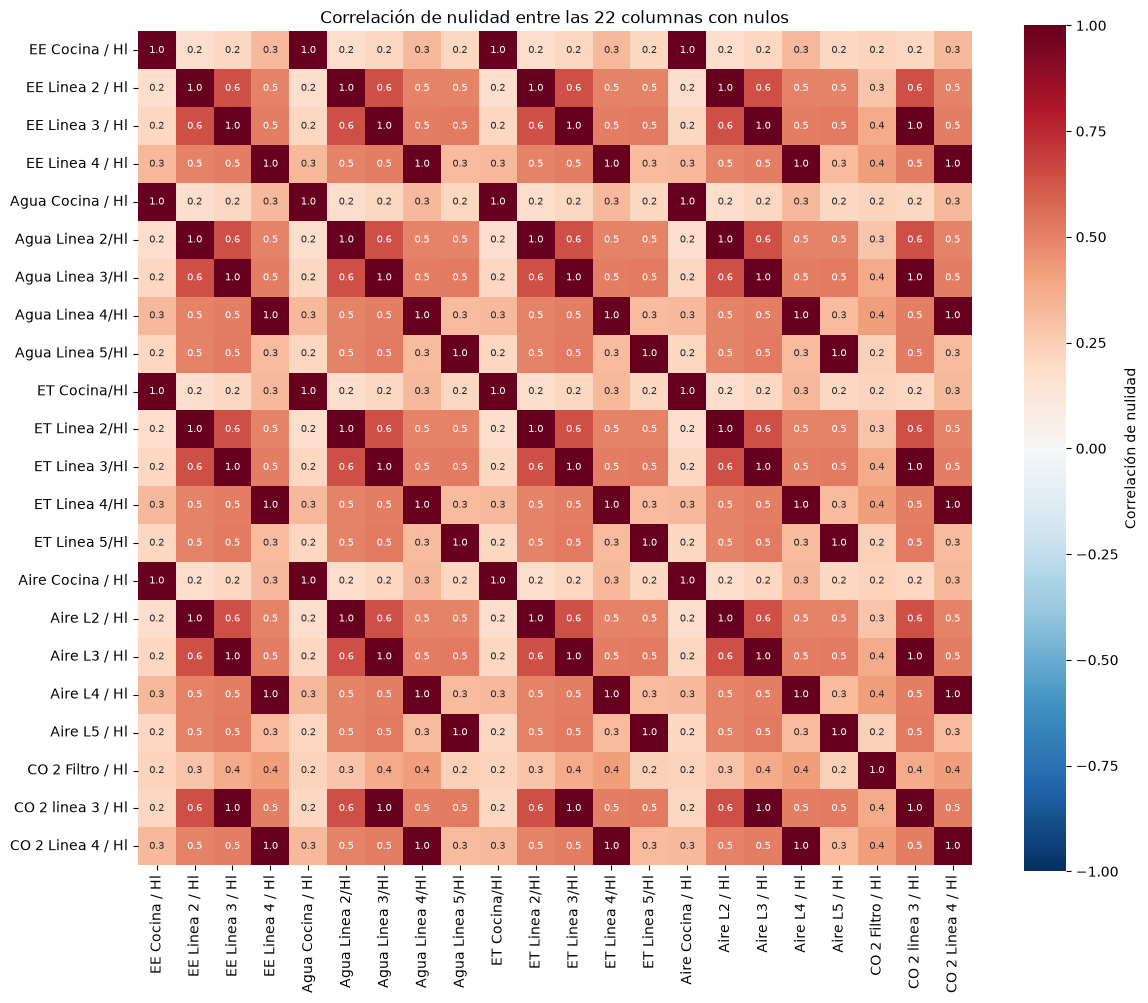

In [44]:
cols_restantes = df_tramo.columns[df_tramo.isna().any()]
corr_nul = df_tramo[cols_restantes].isna().corr()
corr_nul.index = corr_nul.columns = [c.split(" | ", 1)[-1] for c in cols_restantes]

plt.figure(figsize=(12, 10))
sns.heatmap(corr_nul, cmap="RdBu_r", vmin=-1, vmax=1, annot=True, fmt=".1f",
            annot_kws={"size": 7}, square=True, cbar_kws={"label": "Correlación de nulidad"})
plt.title(f"Correlación de nulidad entre las {len(corr_nul)} columnas con nulos")
plt.tight_layout()
plt.show()

Acá claramente hay una relación entre las lineas de producción. La voy a ordenar por area y ver:

Cocina: EE Cocina / Hl, Agua Cocina / Hl, ET Cocina/Hl, Aire Cocina / Hl
Línea 2: EE Linea 2 / Hl, Agua Linea 2/Hl, ET Linea 2/Hl, Aire L2 / Hl
Línea 3: EE Linea 3 / Hl, Agua Linea 3/Hl, ET Linea 3/Hl, Aire L3 / Hl, CO 2 linea 3 / Hl
Línea 4: EE Linea 4 / Hl, Agua Linea 4/Hl, ET Linea 4/Hl, Aire L4 / Hl, CO 2 Linea 4 / Hl
Línea 5: Agua Linea 5/Hl, ET Linea 5/Hl, Aire L5 / Hl
Filtro: CO 2 Filtro / Hl


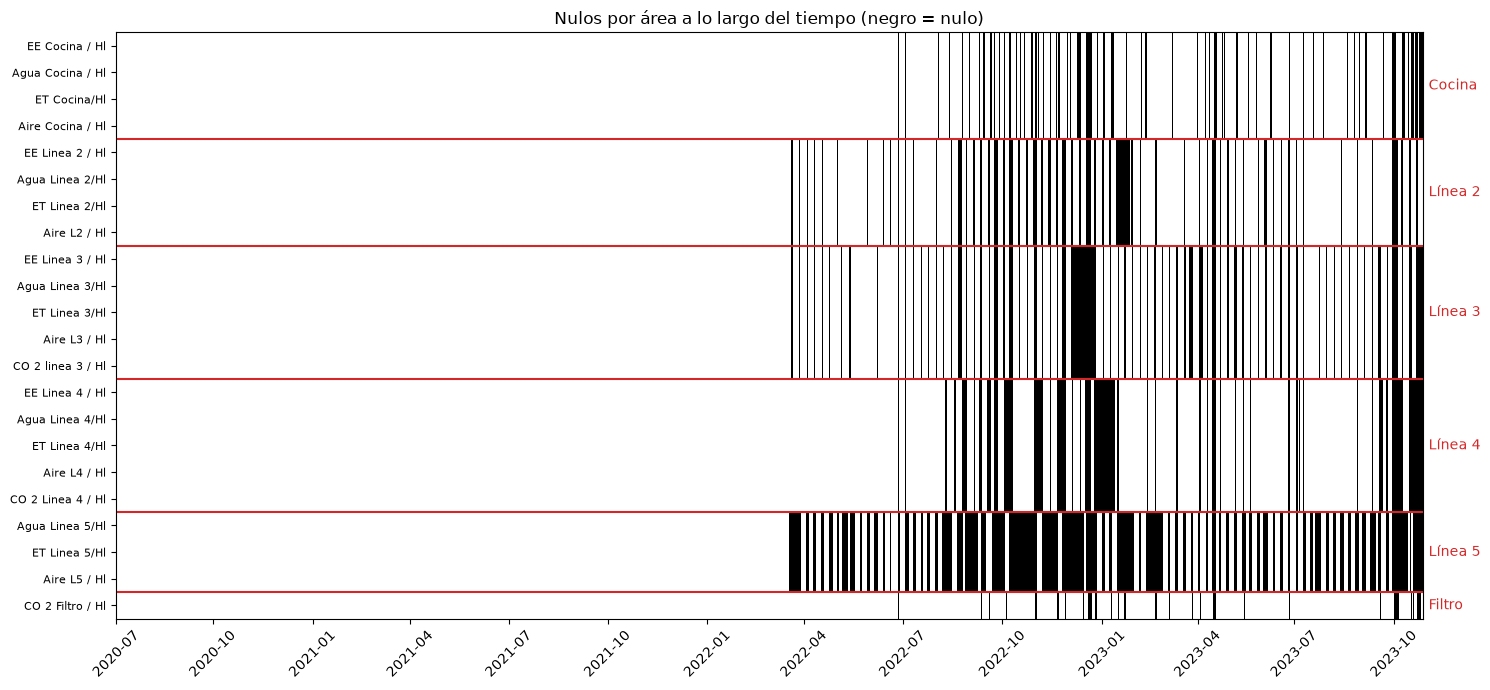

In [45]:
def linea_de(col):
    """Devuelve el área (Cocina, Línea 2-5, Filtro) según el nombre de la columna."""
    nombre = col.split(" | ", 1)[-1]
    patrones = [("Cocina", r"Cocina"), ("Filtro", r"Filtro")] + \
               [(f"Línea {n}", rf"L(?:inea)?\s*{n}\b") for n in [2, 3, 4, 5]]
    for area, patron in patrones:
        if re.search(patron, nombre, flags=re.IGNORECASE):
            return area
    return "Otra"

orden = ["Cocina", "Línea 2", "Línea 3", "Línea 4", "Línea 5", "Filtro", "Otra"]
cols_restantes = df_tramo.columns[df_tramo.isna().any()]
area = pd.Series({c: linea_de(c) for c in cols_restantes})
area = area.sort_values(key=lambda s: s.map(orden.index), kind="stable")

# Listado por área
for nombre_area, cols in area.groupby(area, sort=False):
    print(f"{nombre_area}: {', '.join(c.split(' | ', 1)[-1] for c in cols.index)}")

# Matriz: filas = columnas agrupadas por área, columnas = días
matriz = df_tramo.sort_values("DIA").set_index("DIA")[area.index].isna().T
fechas = matriz.columns

fig, ax = plt.subplots(figsize=(15, 7))
ax.imshow(matriz.to_numpy(), aspect="auto", cmap="Greys", interpolation="nearest")  # negro = nulo

ax.set_yticks(range(len(area)))
ax.set_yticklabels([c.split(" | ", 1)[-1] for c in area.index], fontsize=8)

marcas = np.where(fechas.is_month_start & fechas.month.isin([1, 4, 7, 10]))[0]
ax.set_xticks(marcas)
ax.set_xticklabels(fechas[marcas].strftime("%Y-%m"), rotation=45)

# Separadores y nombre de cada área a la derecha
limites = area.groupby(area, sort=False).size().cumsum()
inicio = 0
for nombre_area, fin in limites.items():
    if fin < len(area):
        ax.axhline(fin - 0.5, color="tab:red", linewidth=1.5)
    ax.text(len(fechas) + 5, (inicio + fin - 1) / 2, nombre_area, va="center", fontsize=10,
            color="tab:red", clip_on=False)
    inicio = fin

ax.set_title("Nulos por área a lo largo del tiempo (negro = nulo)")
plt.tight_layout()
plt.show()

Ahí están claras las relaciones entre líneas y sus nulos.

Lo que voy a hacer es codificar cuando una línea estuvo parada, y despues voy a imputar por el promedio de los vecinos, como hice para los otros nulos. 

In [46]:
df_lineas = df_tramo.copy()

# Indicador por área: 1 si ese día faltaban los datos del área (antes de imputar)
for nombre_area, cols in area.groupby(area, sort=False):
    df_lineas[f"nulo_{nombre_area}"] = df_lineas[cols.index].isna().any(axis=1).astype(int)

# Columnas de las que sale cada indicador, para que el pipeline los arme igual
registro_columnas["indicadores_nulos"] = {f"nulo_{a}": list(cols.index) for a, cols in area.groupby(area, sort=False)}
ruta_columnas.write_text(json.dumps(registro_columnas, ensure_ascii=False, indent=2), encoding="utf-8")

# Largo promedio de los huecos por columna (justifica imputar por vecinos)
nulos_area = df_lineas[area.index].isna()
tramos_area = (nulos_area & ~nulos_area.shift(fill_value=False)).sum()
largo = (nulos_area.sum() / tramos_area).groupby(area).mean().reindex(orden).dropna()
display(largo.round(1))

# Imputación columna por columna con sus vecinos en el tiempo
df_lineas = imputar_promedio_anteriores(df_lineas, list(area.index))

registrar_tratamiento(list(area.index), "promedio_anteriores")

matriz_nulidad(df_lineas, titulo="Matriz de nulidad — después de imputar por línea")

Cocina     1.5
Línea 2    1.9
Línea 3    1.8
Línea 4    3.2
Línea 5    4.9
Filtro     1.5
dtype: float64

promedio_anteriores: 22 columnas registradas en tratamientos_EDA.json
No hay columnas con nulos.


## Columnas con valores negativos

Hago un df con los negativos:

In [47]:
def negativos_por_columna(datos, excluir=("DIA",), col_fecha="DIA"):
    """Tabla de columnas con valores negativos: cuántos, el mínimo y entre qué fechas aparecen."""
    x = datos.drop(columns=list(excluir)).select_dtypes("number")
    neg = x < 0
    cols = neg.columns[neg.any()]
    if len(cols) == 0:
        print("No hay valores negativos.")
        return pd.DataFrame()

    fechas = datos[col_fecha]
    tabla = pd.DataFrame({
        "n negativos": neg[cols].sum(),
        "% negativos": neg[cols].mean().mul(100).round(2),
        "mínimo": x[cols].min(),
    })
    return tabla.sort_values("n negativos", ascending=False)


def pasar_a_positivo(datos, columnas):
    """Devuelve una copia con las `columnas` en valor absoluto."""
    df = datos.copy()
    df[columnas] = df[columnas].abs()
    return df


In [48]:
tabla_neg = negativos_por_columna(df_lineas)
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(tabla_neg)

,n negativos,% negativos,mínimo
Consolidado EE | Resto Serv (Kw),40,3.32,-5.535738e+06
Consolidado KPI | EE Resto Serv / Hl,39,3.24,-7.074199e+02
Consolidado Aire | Aire Servicios (M3),25,2.07,-1.489944e+05
Consolidado KPI | Aire Servicios / Hl,24,1.99,-6.528977e+01
Consolidado EE | Restos Planta (Kw),18,1.49,-4.492792e+06
Consolidado KPI | EE Resto Planta / Hl,15,1.24,-5.876004e+02
Consolidado KPI | ET Linea 3/Hl,11,0.91,-7.990921e+00
Consolidado EE | Bodega (Kw),7,0.58,-6.247000e+03
Consolidado EE | Prod Agua (Kw),7,0.58,-2.936790e+05
Consolidado EE | Linea 2 (Kw),6,0.50,-2.545500e+02


Me parecen interesantes los restos. los que tienen muy pocos valores, los voy a imputar con vecinos anteriores y listo.

In [49]:
# Columnas que se dejan como están: codificación cíclica (negativos legítimos) y los Restos (se analizan aparte)
es_ciclica = tabla_neg.index.str.endswith(("_sin", "_cos"))
es_resto = tabla_neg.index.str.contains("Resto", case=False)

cols_neg_imputar = list(tabla_neg.index[~es_ciclica & ~es_resto])
print(f"Columnas a imputar: {len(cols_neg_imputar)} | valores negativos: {(df_lineas[cols_neg_imputar] < 0).sum().sum()}")

df_neg = imputar_promedio_anteriores(df_lineas, cols_neg_imputar, invalidar_negativos=True)
registrar_tratamiento(cols_neg_imputar, "promedio_anteriores_sin_negativos")

tabla_neg = negativos_por_columna(df_neg)
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(tabla_neg)

Columnas a imputar: 27 | valores negativos: 136
promedio_anteriores_sin_negativos: 27 columnas registradas en tratamientos_EDA.json


,n negativos,% negativos,mínimo
Consolidado EE | Resto Serv (Kw),40,3.32,-5.535738e+06
Consolidado KPI | EE Resto Serv / Hl,39,3.24,-7.074199e+02
Consolidado EE | Restos Planta (Kw),18,1.49,-4.492792e+06
Consolidado KPI | EE Resto Planta / Hl,15,1.24,-5.876004e+02


Ahora que (a propósito) imputé los valores que seguramente eran simples errores, me quedan las 4 columnas con Resto que me hacen ruido, por que no las encontraba en la explicación del dataset.

Nobleza obliga, Claude encontró la relación que tienen con el resto de las columnasa; son restas de la producción total - las diferentes areas, para revisar los medidores. Como estas son combinaciones de las otras columnas, lo que voy a hacer es borrarlas (me imagino que hubieran saltado en los filtros de correlación más adelante). 

In [50]:
cols_resto = [c for c in df_neg.columns if "resto" in c.lower()]
print(f"Columnas Resto a borrar: {len(cols_resto)}")
for c in cols_resto:
    print(f"  - {c}")

df_sin_resto = df_neg.drop(columns=cols_resto)
print(f"Columnas: {df_neg.shape[1]} -> {df_sin_resto.shape[1]}")

registrar_borradas("restos_redundantes", cols_resto)

Columnas Resto a borrar: 6
  - Consolidado KPI | EE Resto Serv / Hl
  - Consolidado KPI | EE Resto Planta / Hl
  - Consolidado EE | Resto Serv (Kw)
  - Consolidado EE | Restos Planta (Kw)
  - Consolidado KPI | Meta EE Resto Serv
  - Consolidado KPI | Meta EE Resto Planta
Columnas: 346 -> 340
restos_redundantes: 6 columnas registradas en tratamientos_EDA.json


## Columnas Identicas y con todos 0s

Primero veo cuales tienen 0 en todos sus valores.

In [51]:
x_num = df_sin_resto.drop(columns="DIA")
cols_cero = list(x_num.columns[(x_num == 0).all()])
print(f"Columnas con todos sus valores en 0: {len(cols_cero)} de {x_num.shape[1]}")

Columnas con todos sus valores en 0: 18 de 339


In [52]:
df_sin_cero = df_sin_resto.drop(columns=cols_cero)
print(f"Columnas: {df_sin_resto.shape[1]} -> {df_sin_cero.shape[1]}")
registrar_borradas("columnas_en_cero", cols_cero)

Columnas: 340 -> 322
columnas_en_cero: 18 columnas registradas en tratamientos_EDA.json


Y ahora veo las columnas que son idénticas:

In [53]:
def columnas_identicas(datos, excluir=("DIA",)):
    """Agrupa las columnas que tienen exactamente los mismos valores en todas las filas.
    Devuelve una lista de grupos (cada grupo, una lista de columnas en el orden del df)."""
    x = datos.drop(columns=list(excluir))
    firma = x.T.apply(tuple, axis=1)   # todos los valores de la columna, en orden
    grupos = firma.groupby(firma, sort=False).groups
    return [list(cols) for cols in grupos.values() if len(cols) > 1]

# Las metas se excluyen: aunque haya metas con los mismos valores, cada una va con su propio KPI
metas_ident = [c for c in df_sin_cero.columns if c.split(" | ", 1)[-1].strip().lower().startswith("meta")]
grupos_ident = columnas_identicas(df_sin_cero, excluir=("DIA", *metas_ident))

In [54]:
# En cada grupo se queda una sola columna: Frio o target si están, si no la de Consolidado, si no la primera
def elegir(grupo):
    for col in grupo:
        if col in ("target", "Consolidado EE | Frio (Kw)"):
            return col
    return next((c for c in grupo if c.startswith("Consolidado")), grupo[0])

ident_borrar = [c for g in grupos_ident for c in g if c != elegir(g)]
df_sin_ident = df_sin_cero.drop(columns=ident_borrar)

print(f"Columnas: {df_sin_cero.shape[1]} -> {df_sin_ident.shape[1]}")
print(f"Quedan grupos idénticos: {len(columnas_identicas(df_sin_ident, excluir=('DIA', *metas_ident)))}")
registrar_borradas("columnas_identicas", ident_borrar)

Columnas: 322 -> 298
Quedan grupos idénticos: 0
columnas_identicas: 24 columnas registradas en tratamientos_EDA.json


De acá en adelante el EDA sigue con los datos ya tratados (nulos, negativos, columnas en 0 e idénticas):

In [55]:
df_limpio = df_sin_ident.copy()
print(f"df_unido {df_unido.shape} -> df_limpio {df_limpio.shape} | nulos: {df_limpio.isna().sum().sum()}")

df_unido (1205, 386) -> df_limpio (1205, 298) | nulos: 0


## Rango de valores

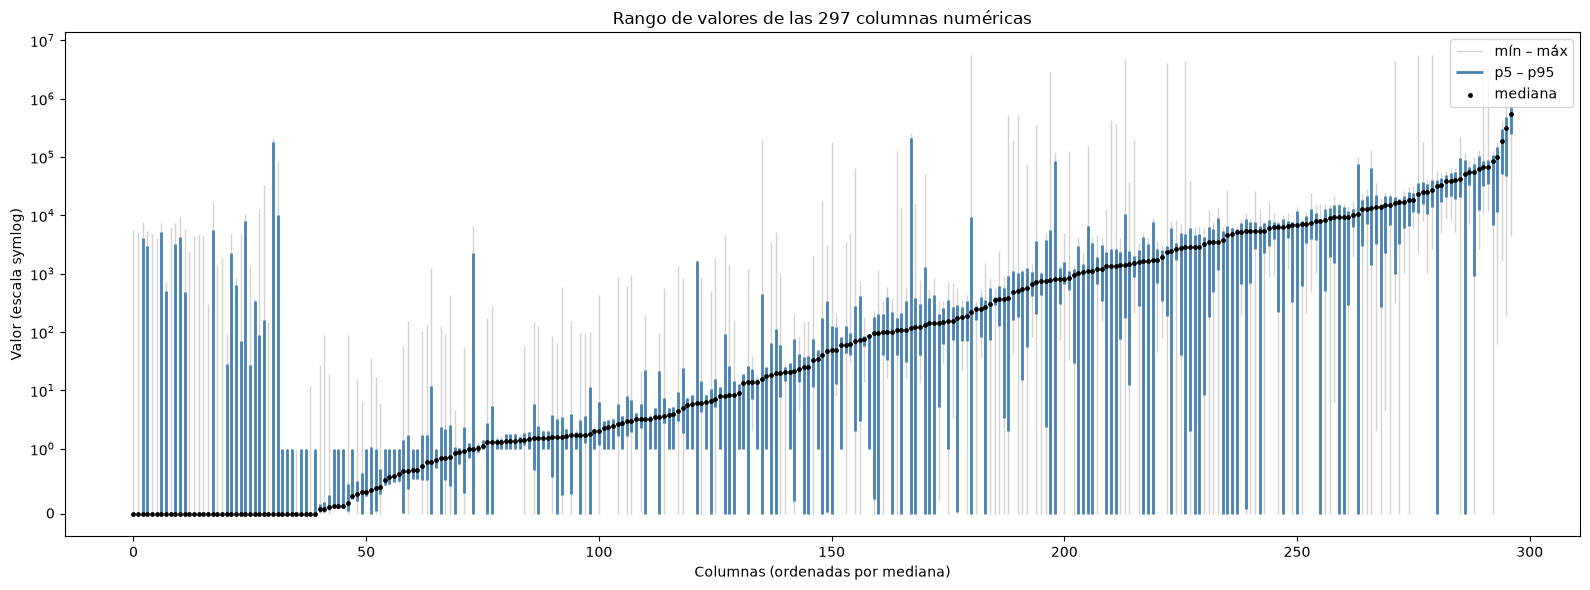

In [56]:
cols_num = [c for c in df_limpio.columns if c not in ("DIA", "imputado", "target_imputado")]
X = df_limpio[cols_num].astype(float)
# Resumen por columna
r = pd.DataFrame({
    "min": X.min(),
    "p5":  X.quantile(0.05),
    "mediana": X.median(),
    "p95": X.quantile(0.95),
    "max": X.max(),
}).dropna()

# Escala simétrica-log para poder mostrar ceros y negativos
r = r.sort_values("mediana").reset_index()
x = np.arange(len(r))

fig, ax = plt.subplots(figsize=(16, 6))
ax.vlines(x, r["min"], r["max"], color="lightgray", lw=1, label="mín – máx")
ax.vlines(x, r["p5"], r["p95"], color="steelblue", lw=2, label="p5 – p95")
ax.scatter(x, r["mediana"], color="black", s=6, zorder=3, label="mediana")

ax.set_yscale("symlog", linthresh=1)
ax.set_xlabel("Columnas (ordenadas por mediana)")
ax.set_ylabel("Valor (escala symlog)")
ax.set_title(f"Rango de valores de las {len(r)} columnas numéricas")
ax.legend()
plt.tight_layout()
plt.show()

De este grafico podemos ver que hay una gran variedad en el rango de valores de las columnas. La barra azul indica en donde esta ubicado el 90% de los datos, y que en la mayoria de los casos, la mediana (punto negro) esta lejos de encontrarse en el medio de la misma barra.

Los casos donde no hay barra es porque los datos son constantes, ademas tambien podemos ver que en los datos con mayor escala es donde la mediana mas se ajusta a la barra del 90% de distribucion.

Tambien podemos ver que la barra gris (va desde el min al max) es en muchos casos mas larga, sobrepasa, la barra azul, lo que indica la presencia de outliers.


### Outliers Puntuales

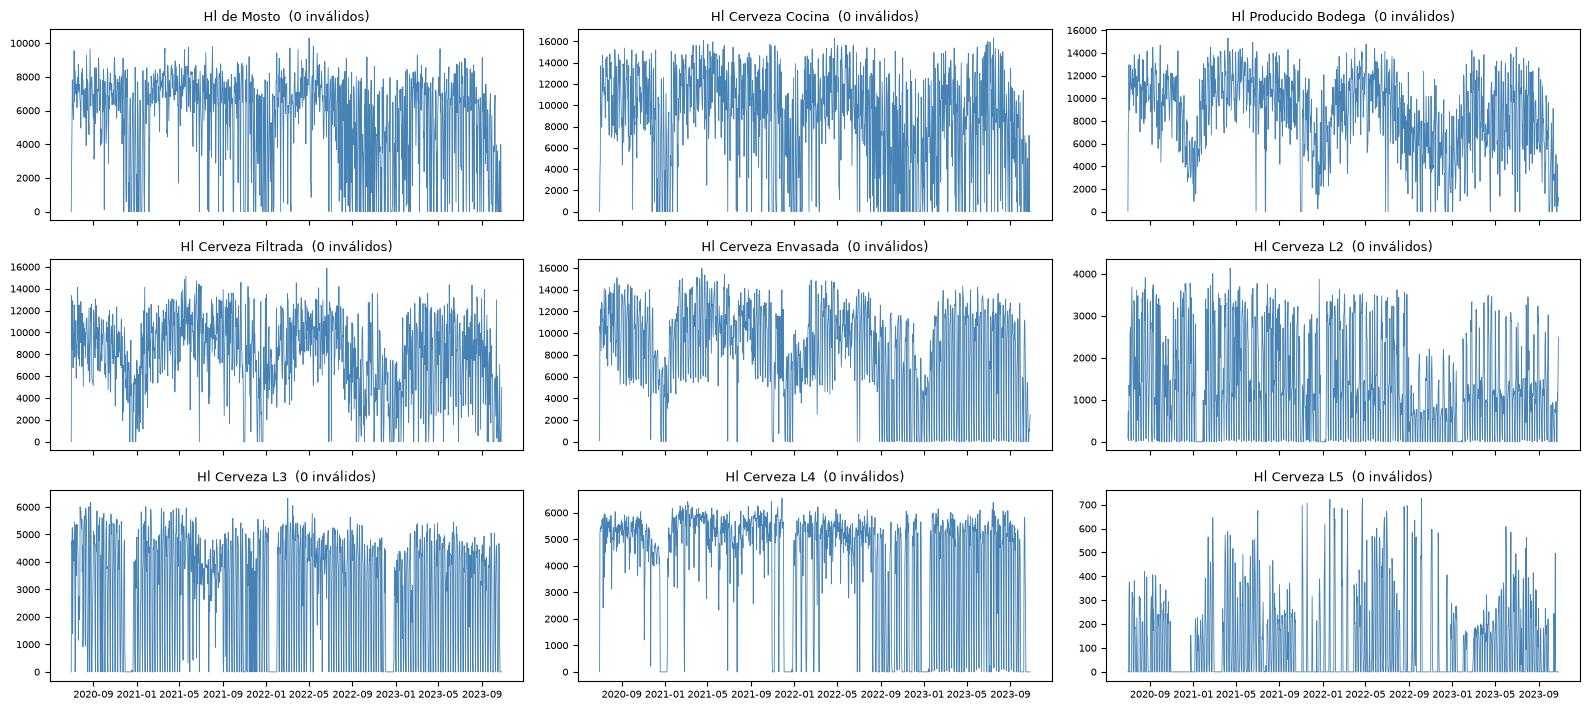

In [57]:
# Columnas de la hoja Consolidado Produccion
cols_hoja_prod = [c for c in df_limpio.columns if c.startswith("Consolidado Produccion | ")]
X = df_limpio[cols_hoja_prod].astype(float)

# Inválido: negativo, o más de 10 veces el p99 de su columna
p99 = X.quantile(0.99)
invalido = (X < 0) | (X.gt(p99 * 10, axis=1) & (p99 > 0))

n = len(cols_hoja_prod)
filas = (n + 2) // 3
fig, axes = plt.subplots(filas, 3, figsize=(16, 2.4 * filas), sharex=True)
axes = axes.ravel()

for ax, c in zip(axes, cols_hoja_prod):
    s = X[c]
    tope = p99[c] * 1.2
    y = s.clip(upper=tope, lower=-0.1 * tope)
    ax.plot(df_limpio["DIA"], y, lw=0.6, color="steelblue")
    bad = invalido[c]
    ax.scatter(df_limpio.loc[bad, "DIA"], y[bad], color="red", s=28, zorder=3)
    ax.set_title(f"{c.split(' | ', 1)[1]}  ({int(bad.sum())} inválidos)", fontsize=9)
    ax.tick_params(labelsize=7)

for ax in axes[n:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Patrones en la producción

Despues de buscar como funciona la cadena de producción de la cerveza, lo resumo en esto: 

- Molís, filtras, y hervís para llegar al mosto. Despues de hervirlo, se tiene que enfriar rapidamente para que no se arruine. 
    - Aca trabaja HL de Mosto, HL Cerveza Cocina.
- Dejas el mosto fermentando. Fermentar a su vez causa calor, por lo tanto hay que seguir enfriando para que no se arruine. Participa ahí Hl Producido Bodega.
- Se tiene que filtrar la cerveza a 0 grados 'para que no se enturbie', y los tanques de cerveza filtrada también quedan fríos. Trabaja Hl Cerveza Filtrada.
- Envasado son 4 líneas de producción, HL Cerveza Ln y su consolidado de Hl Cerveza envasada.


In [58]:
# Producción por etapa del proceso, en el orden del proceso
etapas = {
    "Mosto": "Consolidado Produccion | Hl de Mosto",
    "Cocina": "Consolidado Produccion | Hl Cerveza Cocina",
    "Bodega": "Consolidado Produccion | Hl Producido Bodega",
    "Envasada": "Consolidado Produccion | Hl Cerveza Envasada",
}
prod = df_limpio.set_index("DIA")[list(etapas.values())].rename(columns={v: k for k, v in etapas.items()})
mediana = prod.median()

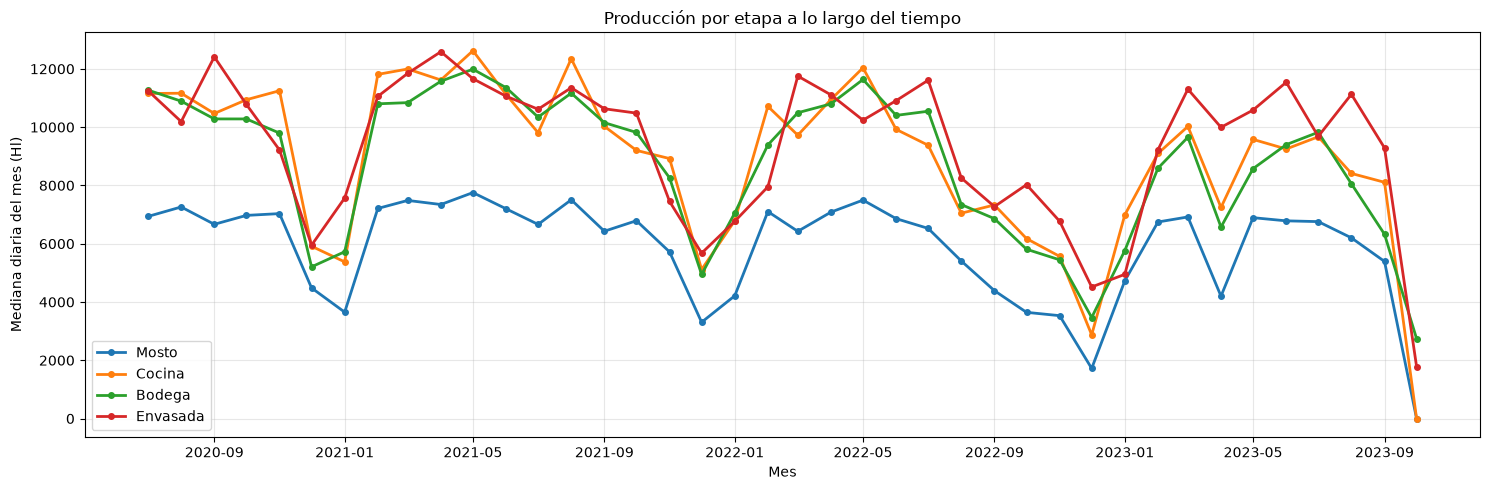

In [59]:
# Evolución mensual de la producción por etapa
mensual = prod.resample("MS").median()

fig, ax = plt.subplots(figsize=(15, 5))
for c in mensual.columns:
    ax.plot(mensual.index, mensual[c], lw=2, marker="o", markersize=4, label=c)
ax.set_xlabel("Mes")
ax.set_ylabel("Mediana diaria del mes (Hl)")
ax.set_title("Producción por etapa a lo largo del tiempo")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

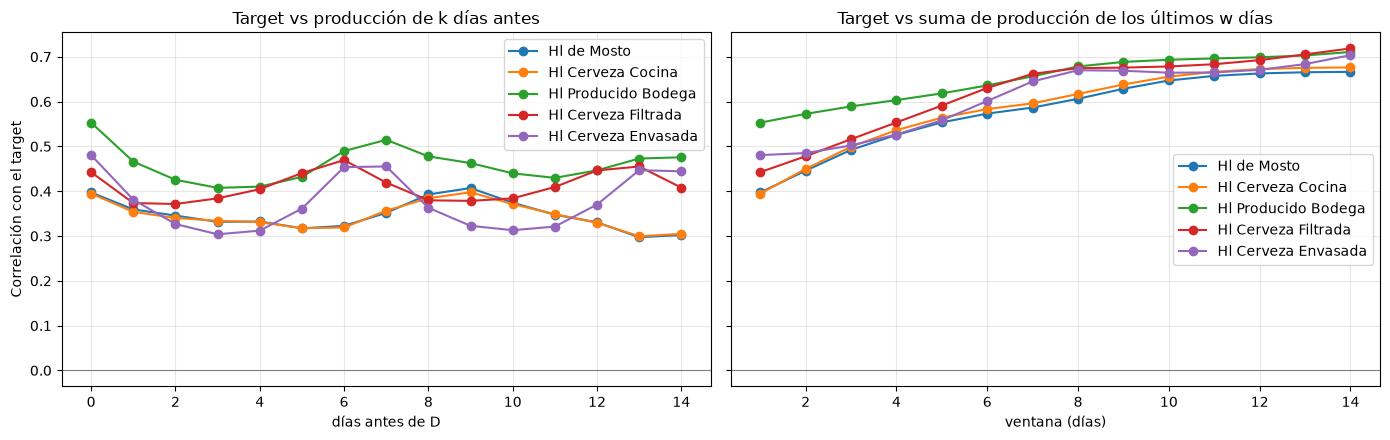

In [60]:
cols_prod = [
    "Consolidado Produccion | Hl de Mosto",
    "Consolidado Produccion | Hl Cerveza Cocina",
    "Consolidado Produccion | Hl Producido Bodega",
    "Consolidado Produccion | Hl Cerveza Filtrada",
    "Consolidado Produccion | Hl Cerveza Envasada",
]
faltan = [c for c in cols_prod if c not in df_limpio.columns]
print("No están en el df:", faltan) if faltan else None
cols_prod = [c for c in cols_prod if c in df_limpio.columns]

# Calendario continuo (así shift(k) son k días reales) y target = Frio de D+1.
# Los Frio de más de 10 veces el p99 (los días de millones) quedan fuera: sin el tratamiento
# de outliers, esos 3 valores dominan la correlación.
tr = df_limpio.sort_values("DIA").set_index("DIA").asfreq("D")
frio_valido = tr["Consolidado EE | Frio (Kw)"].mask(lambda s: s > s.quantile(0.99) * 10)
tr["target"] = frio_valido.shift(-1)
rezagos = range(0, 15)
corto = {c: c.split(" | ", 1)[-1] for c in cols_prod}

# Correlación del target con la producción de k días antes de D
corr_rezago = pd.DataFrame({corto[c]: [tr["target"].corr(tr[c].shift(k)) for k in rezagos] for c in cols_prod},
                           index=pd.Index(rezagos, name="días antes de D"))

# Correlación del target con la suma de producción de los últimos w días (D-w+1 a D)
ventanas = range(1, 15)
corr_suma = pd.DataFrame({corto[c]: [tr["target"].corr(tr[c].rolling(w).sum()) for w in ventanas] for c in cols_prod},
                         index=pd.Index(ventanas, name="ventana (días)"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
corr_rezago.plot(ax=axes[0], marker="o", title="Target vs producción de k días antes")
corr_suma.plot(ax=axes[1], marker="o", title="Target vs suma de producción de los últimos w días")
axes[0].set_ylabel("Correlación con el target")
for ax in axes:
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

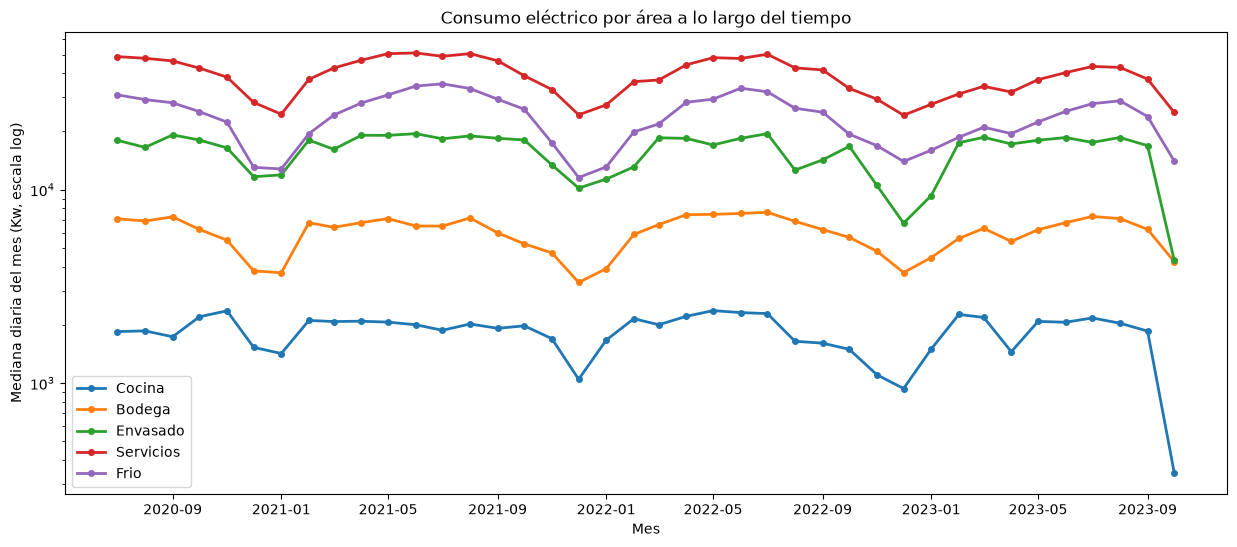

In [61]:
# Evolución mensual del consumo eléctrico por área (escala logarítmica)
areas_ee = {
    "Cocina": "Consolidado EE | Cocina (Kw)",
    "Bodega": "Consolidado EE | Bodega (Kw)",
    "Envasado": "Consolidado EE | Envasado (Kw)",
    "Servicios": "Consolidado EE | Servicios (Kw)",
    "Frio": "Consolidado EE | Frio (Kw)",
}
faltan = [c for c in areas_ee.values() if c not in df_limpio.columns]
print("No están en el df:", faltan) if faltan else None
areas_ee = {k: v for k, v in areas_ee.items() if v in df_limpio.columns}

ee = df_limpio.set_index("DIA")[list(areas_ee.values())].rename(columns={v: k for k, v in areas_ee.items()})
mensual_ee = ee.resample("MS").median()

fig, ax = plt.subplots(figsize=(15, 6))
for c in mensual_ee.columns:
    ax.plot(mensual_ee.index, mensual_ee[c], lw=2, marker="o", markersize=4, label=c)
ax.set_yscale("log")
ax.set_xlabel("Mes")
ax.set_ylabel("Mediana diaria del mes (Kw, escala log)")
ax.set_title("Consumo eléctrico por área a lo largo del tiempo")
ax.legend()

No están en el df: ['Consolidado EE | Filtracion (Kw)']


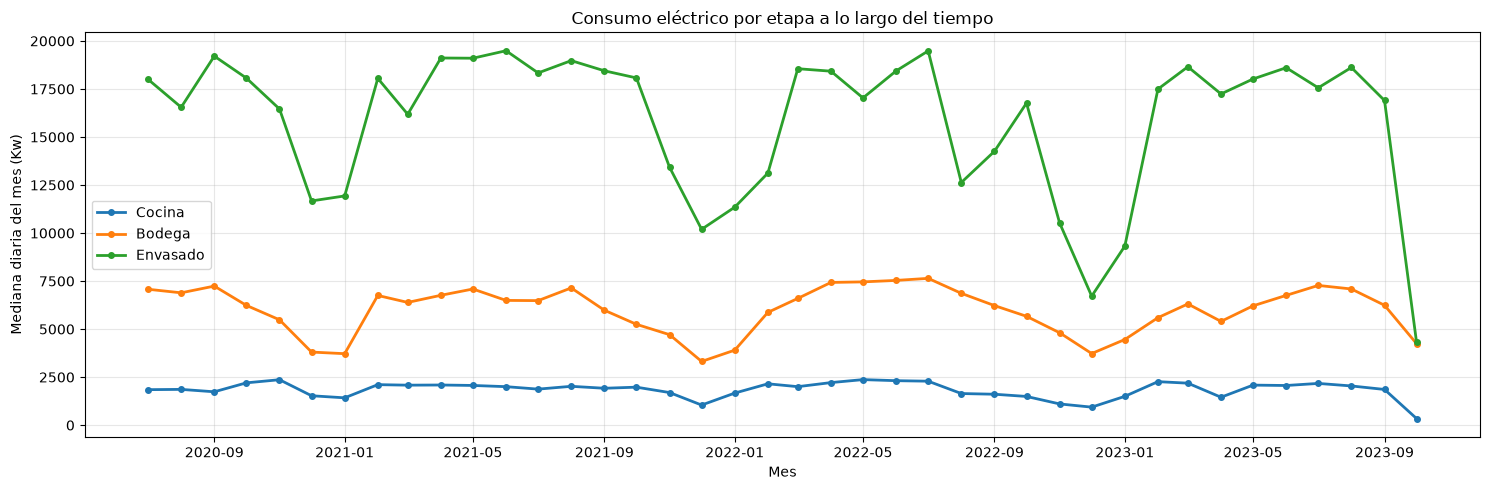

In [62]:
# Evolución mensual del consumo eléctrico por etapa del proceso
areas_ee = {
    "Cocina": "Consolidado EE | Cocina (Kw)",
    "Bodega": "Consolidado EE | Bodega (Kw)",
    "Filtración": "Consolidado EE | Filtracion (Kw)",
    "Envasado": "Consolidado EE | Envasado (Kw)",
}
faltan = [c for c in areas_ee.values() if c not in df_limpio.columns]
print("No están en el df:", faltan) if faltan else None
areas_ee = {k: v for k, v in areas_ee.items() if v in df_limpio.columns}

ee = df_limpio.set_index("DIA")[list(areas_ee.values())].rename(columns={v: k for k, v in areas_ee.items()})
mensual_ee = ee.resample("MS").median()

fig, ax = plt.subplots(figsize=(15, 5))
for c in mensual_ee.columns:
    ax.plot(mensual_ee.index, mensual_ee[c], lw=2, marker="o", markersize=4, label=c)
ax.set_xlabel("Mes")
ax.set_ylabel("Mediana diaria del mes (Kw)")
ax.set_title("Consumo eléctrico por etapa a lo largo del tiempo")
ax.legend()
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

En el eje Y la correlación con frío, y en el eje X cuantos días tiene de diferencia con 0. 
Viendo el primer grafico, nos damos cuenta que el HL de cerveza envasada hace el pico a los 7 días, y despues vuelve a repetir el patrón. 

Hay un cambio semanal en la producción entonces. Bodega es la que más correlación tiene en el mismo día, y aumenta mucho la correlación para cerveza envasada y filtrada en el día 7. 

## Analisis temporal

In [63]:
print("Dia mas viejo:", df_limpio["DIA"].min().date())
print("Dia mas nuevo:", df_limpio["DIA"].max().date())
tot_dias = df_limpio["DIA"].nunique()
print("Cantidad de días/filas en el dataset:", tot_dias)

diferencia = df_limpio["DIA"].max() - df_limpio["DIA"].min()
print("Diferencia en dias segun rango min-max:", diferencia.days)

Dia mas viejo: 2020-07-01
Dia mas nuevo: 2023-10-27
Cantidad de días/filas en el dataset: 1205
Diferencia en dias segun rango min-max: 1213


No quedan tantos días restantes, seguramente sean los que tenian pocos valores en los días.

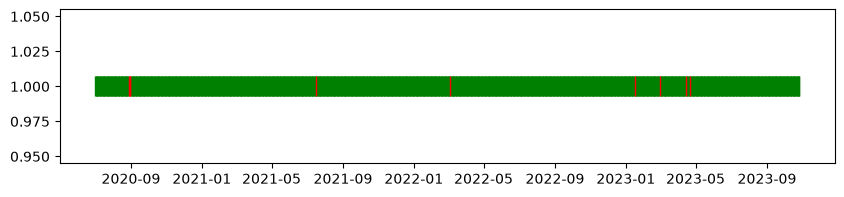

In [64]:
rango = pd.date_range(start=df_limpio['DIA'].min(), end=df_limpio['DIA'].max(), freq='D')

# 3. Ver cuáles faltan
faltantes = rango.difference(df_limpio['DIA'].dt.normalize())

# 4. Graficar de forma simple
plt.figure(figsize=(10, 2))
plt.plot(df_limpio['DIA'], [1] * len(df_limpio), '|', color='green', markersize=15, label='Días con datos')
plt.plot(faltantes, [1] * len(faltantes), '|', color='red', markersize=15, label='Días faltantes')

plt.show()


In [65]:
print(len(faltantes))
print("Dia menor: ", df_limpio['DIA'].min().date(), " Dia mayor: ", df_limpio['DIA'].max().date())
print("Días faltantes en el dataset segun rango min-max: \n", faltantes.date)

9
Dia menor:  2020-07-01  Dia mayor:  2023-10-27
Días faltantes en el dataset segun rango min-max: 
 [datetime.date(2020, 8, 29) datetime.date(2020, 8, 30)
 datetime.date(2020, 8, 31) datetime.date(2021, 7, 16)
 datetime.date(2022, 3, 5) datetime.date(2023, 1, 17)
 datetime.date(2023, 2, 28) datetime.date(2023, 4, 15)
 datetime.date(2023, 4, 21)]


Acá faltan los 9 días que eran los que tenían valores >20; lo que voy a hacer es imputarlos con los valores de sus dos días anteriores.

In [66]:
# Imputo los días faltantes con la mediana de los K días anteriores del mismo mes
observados = df_limpio.copy()
observados["DIA"] = observados["DIA"].dt.normalize()
observados = observados.set_index("DIA").sort_index()
cols_num = list(observados.columns)

base = observados.reindex(rango)             # los faltantes quedan en NaN
base.index.name = "DIA"                      # puede perder el nombre del índice
base["imputado"] = base.index.isin(faltantes)

K = 10  # cuántos días del mismo mes se promedian

for f in faltantes:
    previos = observados.loc[
        (observados.index < f) & (observados.index.month == f.month), cols_num
    ].tail(K)
    base.loc[f, cols_num] = previos.median()
df_limpio = base.reset_index()

print(f"Días imputados: {len(faltantes)} | df_limpio: {df_limpio.shape} | nulos: {df_limpio[cols_num].isna().sum().sum()}")

# Registro la imputación de días faltantes para que el pipeline la reproduzca
registro_columnas["dias_faltantes"] = {
    "dias": [str(f.date()) for f in faltantes],
    "tratamiento": "mediana_k_anteriores_mismo_mes",
    "k": K,
}
ruta_columnas.write_text(json.dumps(registro_columnas, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"dias_faltantes: {len(faltantes)} días registrados en {ruta_columnas.name}")

Días imputados: 9 | df_limpio: (1214, 299) | nulos: 0
dias_faltantes: 9 días registrados en tratamientos_EDA.json


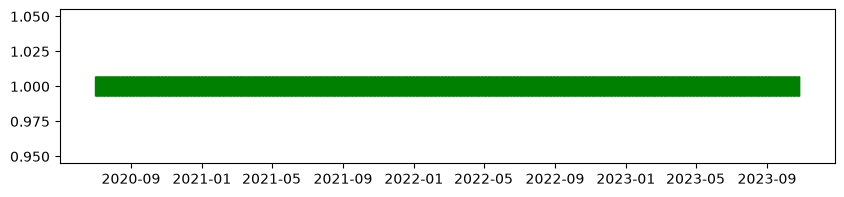

In [67]:
rango = pd.date_range(start=df_limpio['DIA'].min(), end=df_limpio['DIA'].max(), freq='D')

# 3. Ver cuáles faltan
faltantes = rango.difference(df_limpio['DIA'].dt.normalize())

# 4. Graficar de forma simple
plt.figure(figsize=(10, 2))
plt.plot(df_limpio['DIA'], [1] * len(df_limpio), '|', color='green', markersize=15, label='Días con datos')
plt.plot(faltantes, [1] * len(faltantes), '|', color='red', markersize=15, label='Días faltantes')

plt.show()

###  Consumo de Frio a lo largo del tiempo

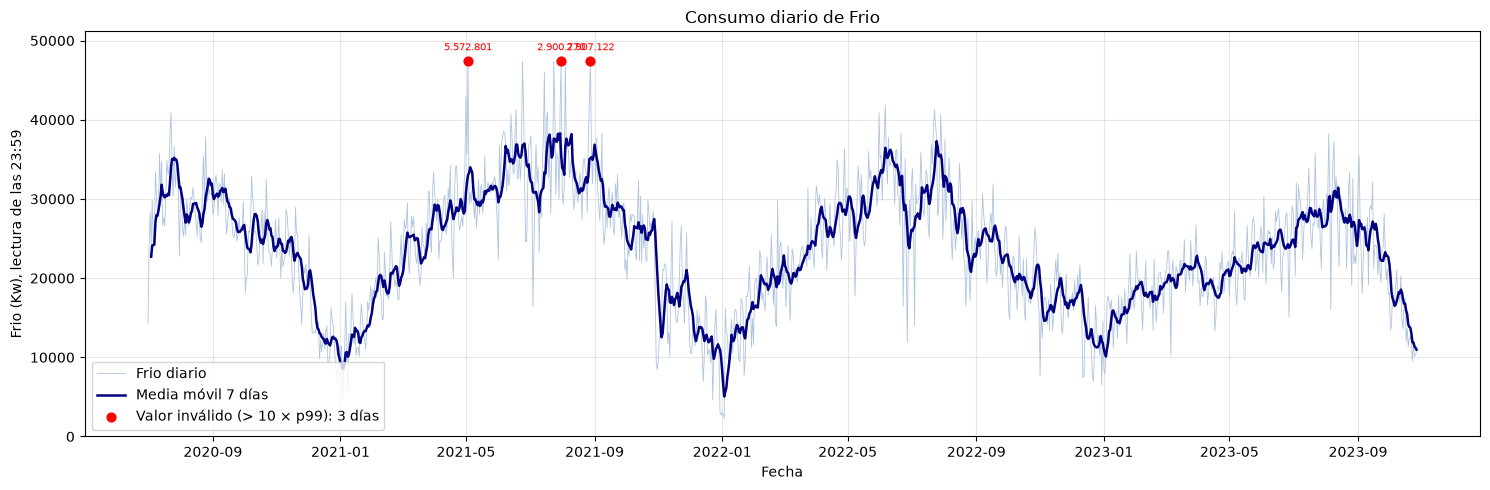

In [68]:
frio = "Consolidado EE | Frio (Kw)"
s = df_limpio.set_index("DIA")[frio].astype(float)

# Días inválidos (más de 10 veces el p99), solo para marcarlos
p99 = s.quantile(0.99)
invalido = s > p99 * 10

# Media móvil de 7 días, sin contar los inválidos
media7 = s.mask(invalido).rolling(7, min_periods=4).mean()

tope = p99 * 1.15
fig, ax = plt.subplots(figsize=(15, 5))

ax.plot(s.index, s.clip(upper=tope), lw=0.6, color="lightsteelblue", label="Frio diario")
ax.plot(media7.index, media7, lw=1.8, color="navy", label="Media móvil 7 días")
ax.scatter(s.index[invalido], np.full(invalido.sum(), tope), color="red", s=40, zorder=3,
           label=f"Valor inválido (> 10 × p99): {int(invalido.sum())} días")

for d, v in s[invalido].items():
    ax.annotate(f"{v:,.0f}".replace(",", "."), (d, tope), textcoords="offset points",
                xytext=(0, 8), ha="center", fontsize=7, color="red")

ax.set_ylim(0, tope * 1.08)
ax.set_xlabel("Fecha")
ax.set_ylabel("Frio (Kw), lectura de las 23:59")
ax.set_title("Consumo diario de Frio")
ax.grid(alpha=0.3)
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

Las linea azul oscura indica la tendencia semanaal, la celeste es el dato de cada dia, los rojos son outliers

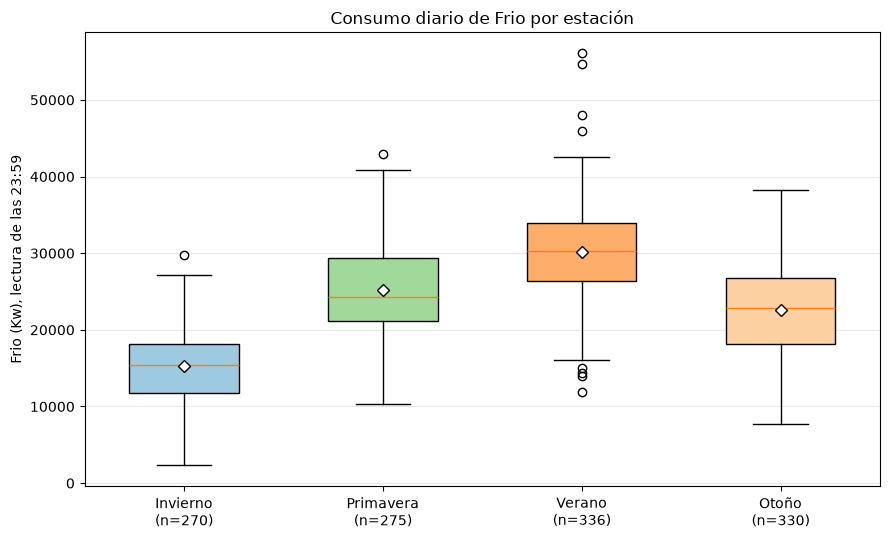

In [69]:
frio = "Consolidado EE | Frio (Kw)"
d = df_limpio[["DIA", frio]].copy()
# Estaciones meteorológicas, hemisferio norte: 0=invierno, 1=primavera, 2=verano, 3=otoño
d["ESTACION"] = d["DIA"].dt.month.map({12: 0, 1: 0, 2: 0, 3: 1, 4: 1, 5: 1,
                                       6: 2, 7: 2, 8: 2, 9: 3, 10: 3, 11: 3})
d[frio] = d[frio].astype(float)

# Sin los valores imposibles (los 3 días de millones)
p99 = d[frio].quantile(0.99)
d = d[d[frio] <= p99 * 10]

nombres = {0: "Invierno", 1: "Primavera", 2: "Verano", 3: "Otoño"}
grupos = [d.loc[d["ESTACION"] == k, frio].dropna() for k in range(4)]

fig, ax = plt.subplots(figsize=(9, 5.5))
bp = ax.boxplot(grupos, showmeans=True, patch_artist=True, widths=0.55,
                meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="black", markersize=6))
ax.set_xticklabels([f"{nombres[k]}\n(n={len(g)})" for k, g in enumerate(grupos)])
for patch, color in zip(bp["boxes"], ["#9ecae1", "#a1d99b", "#fdae6b", "#fdd0a2"]):
    patch.set_facecolor(color)

ax.set_ylabel("Frio (Kw), lectura de las 23:59")
ax.set_title("Consumo diario de Frio por estación")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


Consumo de Frio segun la estacion en la que se esta, a lo largo de todo el periodo, se ve claramente que a mayor temperatura mayor debe de ser el consumo, esto lo relacionamos acorde a la temperatura que hay en esas estaciones, luego analizaremos la temperatura segun las mediciones de Open-Meteo 

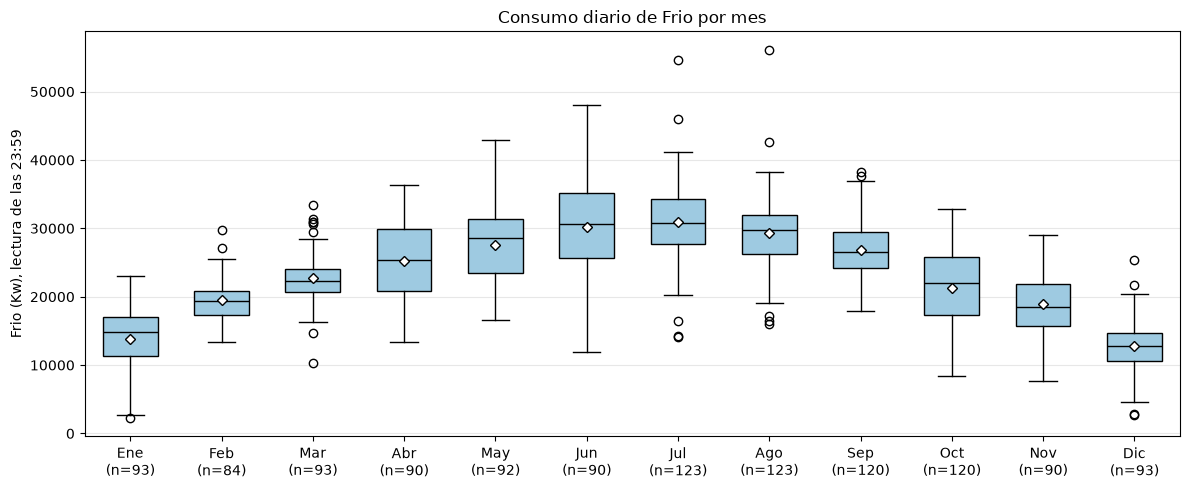

In [70]:
# Consumo de Frio por mes, sin los días de millones
d = df_limpio[["DIA", FRIO]].copy()
d = d[d[FRIO] <= d[FRIO].quantile(0.99) * 10]
d["MES"] = d["DIA"].dt.month

meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
grupos = [d.loc[d["MES"] == m, FRIO] for m in range(1, 13)]

fig, ax = plt.subplots(figsize=(12, 5))
bp = ax.boxplot(grupos, patch_artist=True, showmeans=True, widths=0.6,
                meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="black", markersize=5))
for p in bp["boxes"]:
    p.set_facecolor("#9ecae1")
for m in bp["medians"]:
    m.set_color("black")

ax.set_xticks(range(1, 13))
ax.set_xticklabels([f"{meses[i]}\n(n={len(g)})" for i, g in enumerate(grupos)])
ax.set_ylabel("Frio (Kw), lectura de las 23:59")
ax.set_title("Consumo diario de Frio por mes")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Efecto del Consumo por día

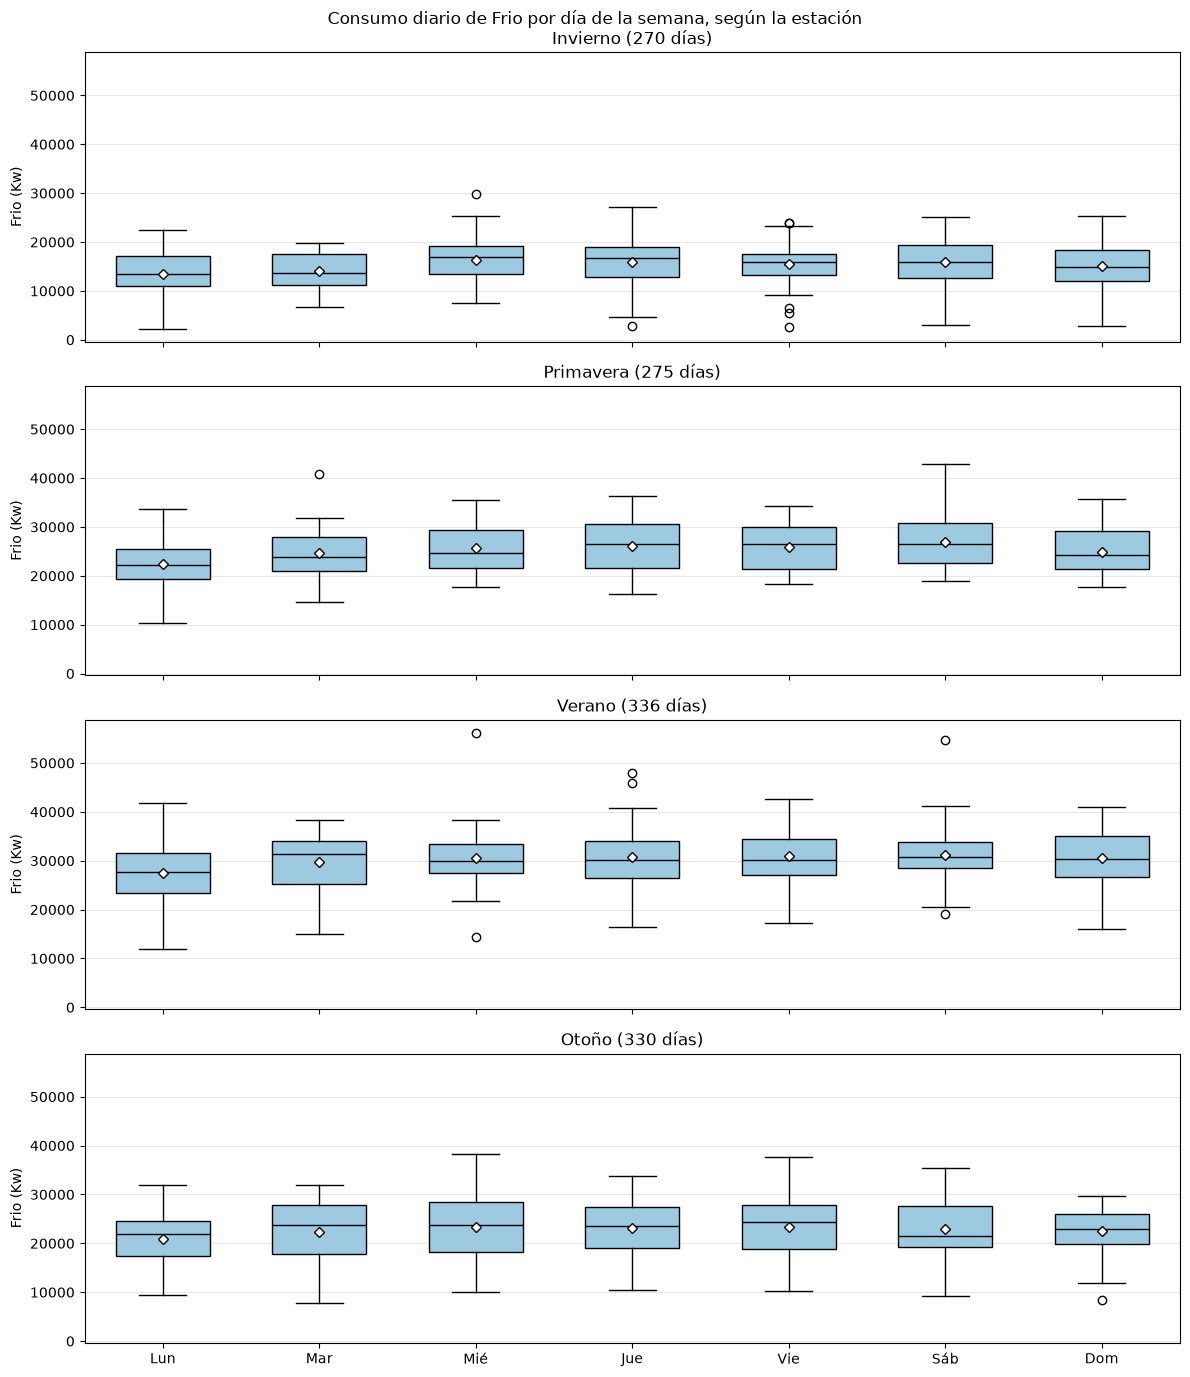

In [71]:
frio = "Consolidado EE | Frio (Kw)"
nombres_est = {0: "Invierno", 1: "Primavera", 2: "Verano", 3: "Otoño"}
dias_sem = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]

d = df_limpio[["DIA", frio]].copy()
d = d[d[frio] <= d[frio].quantile(0.99) * 10]          # sin los valores imposibles (días de millones)
d["DS"] = d["DIA"].dt.day_of_week                     # día de la semana del propio día (0 = lunes)
# Estaciones meteorológicas, hemisferio norte
d["ESTACION"] = d["DIA"].dt.month.map({12: 0, 1: 0, 2: 0, 3: 1, 4: 1, 5: 1,
                                       6: 2, 7: 2, 8: 2, 9: 3, 10: 3, 11: 3})

fig, axes = plt.subplots(4, 1, figsize=(12, 14), sharex=True, sharey=True)
for est, ax in zip(range(4), axes):
    de_est = d[d["ESTACION"] == est]
    grupos = [de_est.loc[de_est["DS"] == i, frio] for i in range(7)]
    bp = ax.boxplot(grupos, patch_artist=True, showmeans=True, widths=0.6,
                    meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="black", markersize=5))
    for p in bp["boxes"]:
        p.set_facecolor("#9ecae1")
    for m in bp["medians"]:
        m.set_color("black")
    ax.set_title(f"{nombres_est[est]} ({len(de_est)} días)")
    ax.set_ylabel("Frio (Kw)")
    ax.grid(axis="y", alpha=0.3)

axes[-1].set_xticks(range(1, 8))
axes[-1].set_xticklabels(dias_sem)
fig.suptitle("Consumo diario de Frio por día de la semana, según la estación")
plt.tight_layout()
plt.show()

De estadística conozco al ANOVA. Lo que voy a hacer es ver si es signficativo el efecto del día:

In [72]:
grupos = [d.loc[d["DS"] == i, frio] for i in range(7)]
F, p = stats.f_oneway(*grupos)
print(f"ANOVA de un factor (Frio según el día de la semana, {len(d)} días)")
print(f"F = {F:.2f} | p-valor = {p:.4f}")
print("El día de la semana tiene un efecto significativo (p < 0,05)" if p < 0.05 else "No hay efecto significativo del día de la semana (p >= 0,05)")

ANOVA de un factor (Frio según el día de la semana, 1211 días)
F = 3.59 | p-valor = 0.0015
El día de la semana tiene un efecto significativo (p < 0,05)


Veo que lo es y por lo tanto voy a mantenerlo en el dataset. Más tarde termino codificando los días con coseno y seno, lo cual tendría que guardar el efecto.

## Crear la Label

In [73]:
# Variable objetivo: Frio (Kw) del día siguiente (D+1), alineado con las features del día D
df_dias = df_limpio.sort_values("DIA").reset_index(drop=True)

# Frio viene definido de arriba como la columna de frio en KW
df_dias["target"] = df_dias[FRIO].shift(-1)

# Saco el último dia:
df_dias = df_dias.dropna(subset=["target"]).reset_index(drop=True)

print(df_dias[["DIA", FRIO, "target"]].head())
print(df_dias.shape)

         DIA  Consolidado EE | Frio (Kw)   target
0 2020-07-01                     14325.0  23954.0
1 2020-07-02                     23954.0  28268.0
2 2020-07-03                     28268.0  24246.0
3 2020-07-04                     24246.0  29885.0
4 2020-07-05                     29885.0  24449.0
(1213, 300)


### Condensadores

In [74]:
# Mismo corte que el preprocesamiento: test y validación = 15 % cada uno, train = el resto (lo más antiguo)
UMBRAL_NIVEL_BAJO, UMBRAL_NIVEL_ALTO, UMBRAL_CEROS = 0.4, 2.5, 0.8

n_test = round(len(df_dias) * 0.15)
fin_train = len(df_dias) - 2 * n_test
q_train = df_dias.iloc[:fin_train]
q_val = df_dias.iloc[fin_train:len(df_dias) - n_test]
print(f"Train hasta {q_train['DIA'].max().date()} | validación {q_val['DIA'].min().date()} -> {q_val['DIA'].max().date()} (test no se mira)")

# Fuera del análisis: Frio y producción (protegidas, como en el descarte por correlación), metas, indicadores y target
def fuera_quiebre(c):
    return (c in ("DIA", "imputado", "target", FRIO)
            or c.startswith(("nulo_", "no_hay_meta", "Consolidado Produccion | "))
            or c.split(" | ", 1)[-1].strip().lower().startswith("meta"))

cols_q = [c for c in df_dias.columns if not fuera_quiebre(c) and df_dias[c].nunique() > 1]

# Referencia: los mismos meses del año en train (la estacionalidad no cuenta como quiebre)
ref = q_train[q_train["DIA"].dt.month.isin(q_val["DIA"].dt.month.unique())]
nivel = q_val[cols_q].mean() / ref[cols_q].mean().replace(0, np.nan)
ceros_ref = (ref[cols_q] == 0).mean()
ceros_val = (q_val[cols_q] == 0).mean()

cambio_nivel = (nivel < UMBRAL_NIVEL_BAJO) | (nivel > UMBRAL_NIVEL_ALTO)
apagada = (ceros_val > UMBRAL_CEROS) & (ceros_ref < 0.5)
cols_quiebre = sorted(nivel.index[(cambio_nivel | apagada).to_numpy()])

print(f"Analizadas: {len(cols_q)} | con quiebre: {len(cols_quiebre)} "
      f"({cambio_nivel.sum()} por nivel, {apagada.sum()} apagadas)")
print(f"Frio con el mismo criterio, como referencia: {q_val[FRIO].mean() / ref[FRIO].mean():.2f}")

tabla_quiebre = pd.DataFrame({"nivel_val/train": nivel, "ceros_train": ceros_ref,
                              "ceros_val": ceros_val}).loc[cols_quiebre]
tabla_quiebre.sort_values("nivel_val/train").round(2).head(10)

Train hasta 2022-10-27 | validación 2022-10-28 -> 2023-04-27 (test no se mira)
Analizadas: 231 | con quiebre: 44 (44 por nivel, 4 apagadas)
Frio con el mismo criterio, como referencia: 0.87


,nivel_val/train,ceros_train,ceros_val
Totalizadores Agua | Glicol Paste L3,0.0,0.98,1.0
Totalizadores Agua | Red Bodega,0.0,0.56,1.0
Totalizadores Agua | Agua Helada Cocina,0.0,0.80,1.0
Totalizadores Efluentes | Totalizador Bba Gas,0.0,1.00,1.0
Totalizadores Energia | KW Atlas 3,0.0,0.78,1.0
Totalizadores Energia | KW Enfr Agua Cocina,0.0,0.80,1.0
Totalizadores Energia | KW Mycom 5,0.0,0.63,1.0
Totalizadores Energia | KW Mycom 2,0.0,0.09,1.0
Totalizadores Produccion | HL Mosto Amstel,0.0,0.98,1.0
Totalizadores Gas y Vapor | VAPOR DE CALDERA 4 KG,0.0,0.41,1.0


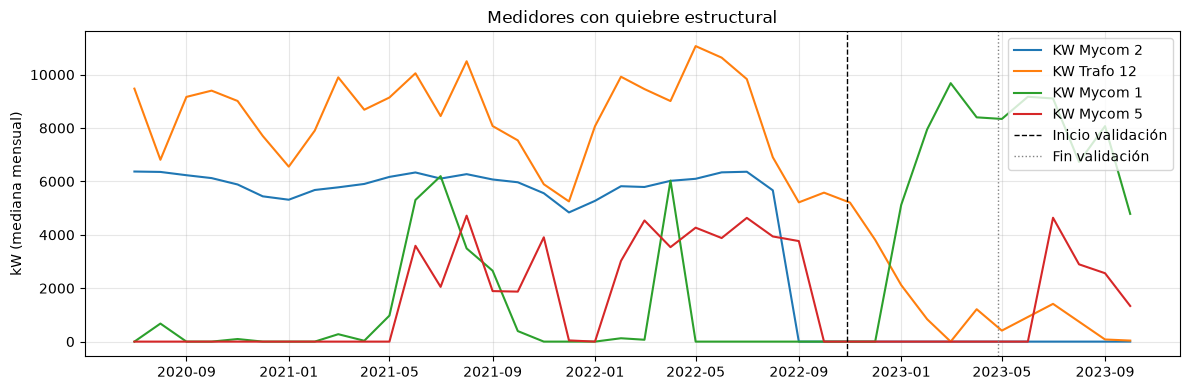

In [75]:
# Media mensual de algunas columnas con quiebre, con el inicio de validación marcado
ejemplos = [c for c in ["Totalizadores Energia | KW Mycom 2", "Totalizadores Energia | KW Trafo 12",
                        "Totalizadores Energia | KW Mycom 1", "Totalizadores Energia | KW Mycom 5"]
            if c in cols_quiebre]
mensual = df_dias.set_index("DIA")[ejemplos].resample("MS").median()

fig, ax = plt.subplots(figsize=(12, 4))
for c in ejemplos:
    ax.plot(mensual.index, mensual[c], label=c.split(" | ")[-1])
ax.axvline(q_val["DIA"].min(), color="black", linestyle="--", linewidth=1, label="Inicio validación")
ax.axvline(q_val["DIA"].max(), color="gray", linestyle=":", linewidth=1, label="Fin validación")
ax.set_ylabel("kW (mediana mensual)")
ax.set_title("Medidores con quiebre estructural")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [76]:
df_dias = df_dias.drop(columns=cols_quiebre)
print(f"df_dias: {df_dias.shape}")
registrar_borradas("quiebre_estructural", cols_quiebre)

df_dias: (1213, 256)
quiebre_estructural: 44 columnas registradas en tratamientos_EDA.json


In [77]:
# Compresores individuales: sale todo Mycom que siga en df_dias (algunos ya salieron por quiebre)
cols_mycom = [c for c in df_dias.columns if "Mycom" in c]
df_dias = df_dias.drop(columns=cols_mycom)
print(f"Compresores borrados acá: {len(cols_mycom)} | df_dias: {df_dias.shape}")
registrar_borradas("compresores_individuales", cols_mycom)

Compresores borrados acá: 4 | df_dias: (1213, 252)
compresores_individuales: 4 columnas registradas en tratamientos_EDA.json


## Analisis de correlaciones

Primero hago la matriz de correlaciones de todo, no espero sacar nada de acá: 

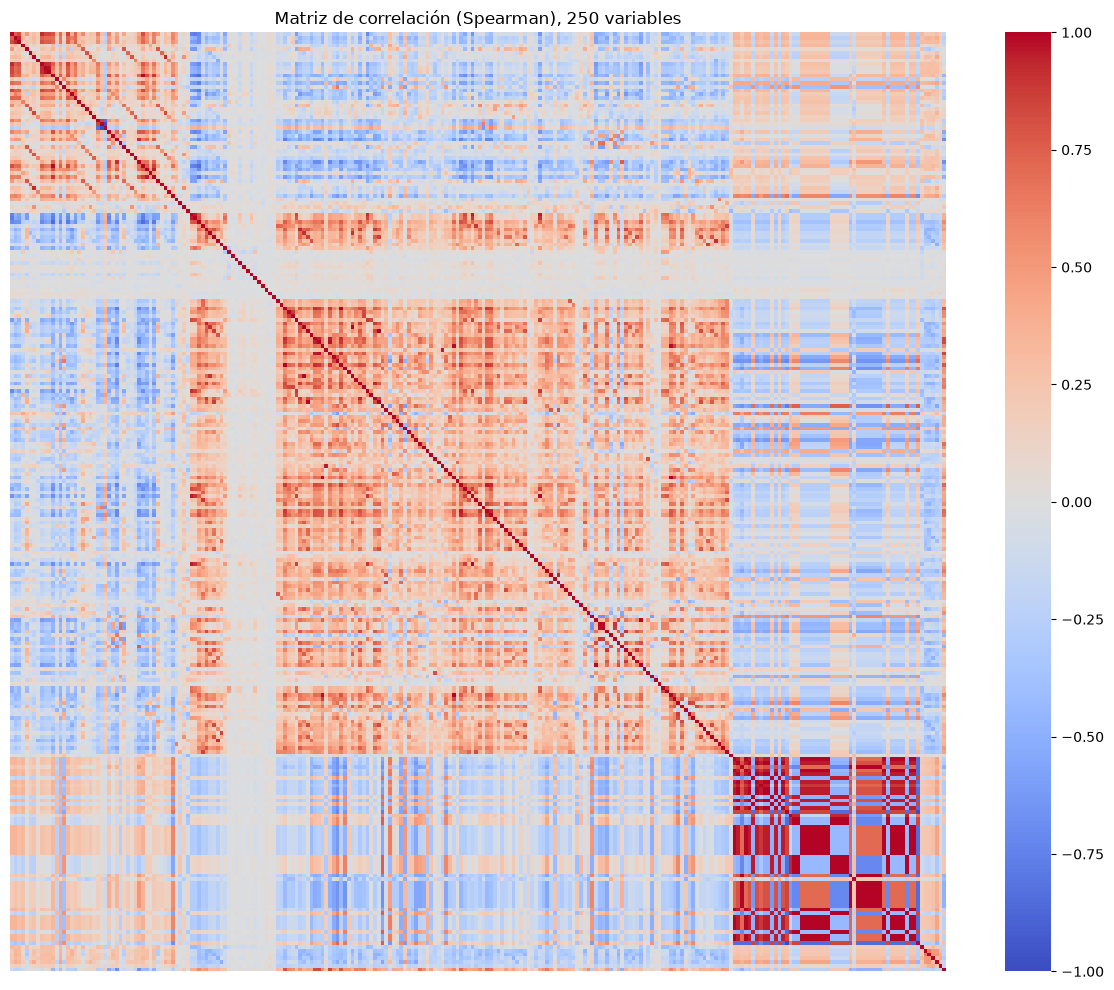

In [78]:
# Matriz de correlación de todas las numéricas + target
num = df_dias.drop(columns=["DIA", "imputado"], errors="ignore").astype(float)
num = num.loc[:, num.nunique() > 1]          # constantes dan NaN en la correlación
M = num.corr(method="spearman")

plt.figure(figsize=(12, 10))
sns.heatmap(M, cmap="coolwarm", vmin=-1, vmax=1, center=0,
            xticklabels=False, yticklabels=False)
plt.title(f"Matriz de correlación (Spearman), {M.shape[0]} variables")
plt.tight_layout()
plt.show()

Ahora busco las 15 más correlacionadas con la label y les hago su matriz de correlación:

Consolidado EE | Frio (Kw)                  0.849
Consolidado EE | Sala Maq (Kw)              0.828
Consolidado EE | Servicios (Kw)             0.824
Consolidado EE | KW Gral Planta             0.789
Consolidado EE | Planta (Kw)                0.784
Consolidado Agua | Agua Planta (Hl)         0.722
Consolidado Agua | Planta de agua (Hl)      0.711
Consolidado KPI | ET Bodega/Hl             -0.693
Totalizadores Energia | KW Cond 5. 6 y 9    0.690
Consolidado KPI | ET Servicios / Hl        -0.683
Consolidado Agua | Produccion (Hl)          0.674
Totalizadores Agua | Agua Cond REC          0.636
Totalizadores Energia | KW Trafo 10         0.633
Totalizadores Energia | KW Trafo 11         0.632
Totalizadores Energia | KW Trafo 9          0.604


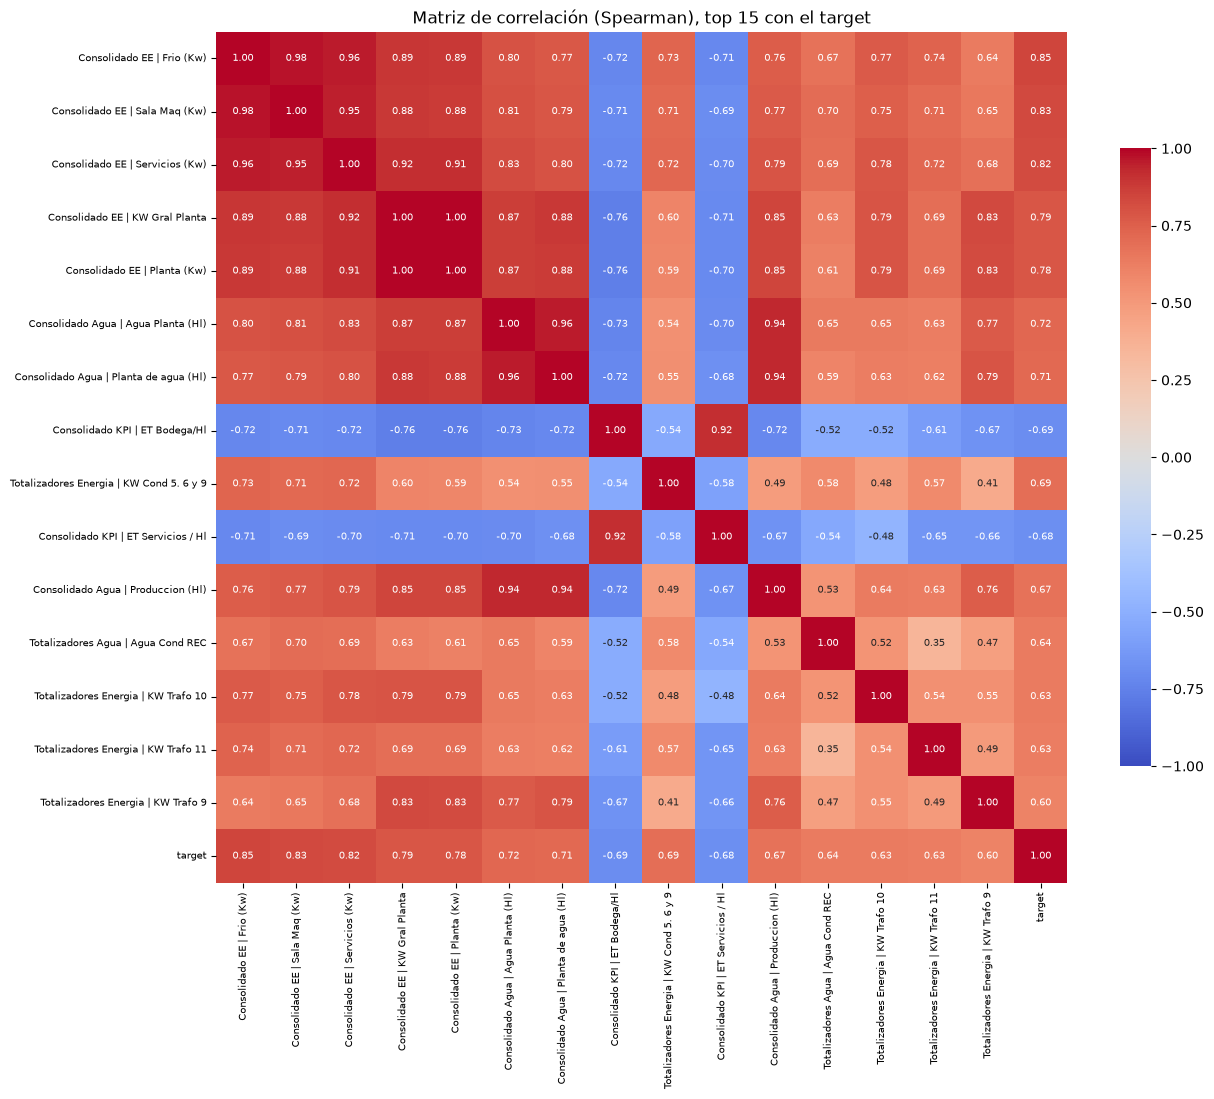

In [79]:
# Top 15 por |correlación| con el target
corr_target = M["target"].drop("target")
top15 = corr_target.abs().nlargest(15).index
print(corr_target[top15].round(3).to_string())

M15 = M.loc[[*top15, "target"], [*top15, "target"]]

plt.figure(figsize=(13, 11))
sns.heatmap(M15, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0,
            square=True, annot_kws={"size": 7}, cbar_kws={"shrink": 0.7})
plt.xticks(fontsize=7, rotation=90)
plt.yticks(fontsize=7)
plt.title("Matriz de correlación (Spearman), top 15 con el target")
plt.tight_layout()
plt.show()

- Que el frio sea la más correlacionada tiene sentido, por que es el valor de ayer. 
- Condensadores y sala de maquinas debe estar todo muy relacionado por ser donde se guardar los compresores/compensadores, es casi todo lo mismo.


No llego a ver buenas relaciones de este heatmap por que siento que la mayoría dicen lo mismo. Lo que voy a hacer es filtrar por multicolinealidad;
- Calculo la correlación para una feature, y evaluo todas las correlaciones. Tomo el umbral y si está por encima, borro la feature que tenga menos correlación con el target.

- Voy a mantener algunas variables que uso mas adelante para el feature engineering: todas las de producción, la de frío (es la más importante).

In [80]:
def descartar_correlacionadas(datos, umbral, col_target="target", proteger=()):
    """Recorre los pares con |rho| > umbral, de mayor a menor, y borra el que menos correlaciona con el target.
    Las columnas de `proteger` nunca se borran: si están en un par, sale la otra; si las dos son protegidas, quedan ambas"""
    X = datos.drop(columns=[col_target])
    rho = X.corr(method="spearman").abs()
    rho_target = X.corrwith(datos[col_target], method="spearman").abs()
    proteger = set(proteger)

    # Cada par una sola vez (triángulo superior), ordenados de mayor a menor correlación
    pares = rho.where(np.triu(np.ones(rho.shape, dtype=bool), k=1)).stack()
    pares = pares[pares > umbral].sort_values(ascending=False)

    borradas = {}   # columna borrada -> (con cuál estaba correlacionada, rho del par)
    for (a, b), r in pares.items():
        if a in borradas or b in borradas:     # si una ya salió, el par ya no existe
            continue
        if a in proteger and b in proteger:    # las dos protegidas: quedan ambas
            continue
        if a in proteger or b in proteger:
            sale, queda = (b, a) if a in proteger else (a, b)
        else:
            sale, queda = (a, b) if rho_target[a] < rho_target[b] else (b, a)
        borradas[sale] = (queda, r)
    return borradas

In [81]:
UMBRAL_CORRELACION = 0.85

num = df_dias.drop(columns=["DIA", "imputado"], errors="ignore").astype(float)
num = num.loc[:, num.nunique() > 1]            # constantes dan NaN en la correlación

# Producción (para el feature engineering) y Frio del día D
cols_protegidas = [FRIO, *[c for c in num.columns if c.startswith("Consolidado Produccion | ")]]
print(f"Protegidas: {len(cols_protegidas)}")

# Metas e indicadores quedan fuera: las metas se usan para las eficiencias y los indicadores los crea el pipeline
cols_fuera = [c for c in num.columns
              if c.split(" | ", 1)[-1].strip().lower().startswith("meta") or c.startswith(("nulo_", "no_hay_meta"))]
print(f"Fuera del descarte: {len(cols_fuera)}")

borradas = descartar_correlacionadas(num.drop(columns=cols_fuera), UMBRAL_CORRELACION, proteger=cols_protegidas)
df_corr = num.drop(columns=list(borradas))

Protegidas: 10
Fuera del descarte: 56


In [82]:
rho_target = num.drop(columns="target").corrwith(num["target"], method="spearman").abs()
detalle = pd.DataFrame.from_dict(borradas, orient="index", columns=["se queda", "rho del par"])
detalle["rho target (sale)"] = rho_target[detalle.index].values
detalle["rho target (queda)"] = rho_target[detalle["se queda"]].values
print(detalle.sort_values("rho del par", ascending=False).round(3).to_string())

                                                                                   se queda  rho del par  rho target (sale)  rho target (queda)
Totalizadores Agua | FC Cocina                          Consolidado Agua | Agua Cocina (Hl)        1.000              0.441               0.441
Totalizadores Energia | KW Linea 3                            Consolidado EE | Linea 3 (Kw)        1.000              0.440               0.441
Consolidado EE | Planta (Kw)                                Consolidado EE | KW Gral Planta        0.999              0.784               0.789
Consolidado EE | Linea 2 (Kw)                            Totalizadores Energia | KW Trafo 8        0.994              0.372               0.387
Totalizadores Energia | Kw Compresores Aire          Consolidado Aire | Aire Producido (M3)        0.994              0.582               0.590
Consolidado KPI | Produccion Agua / Hl             Consolidado KPI | Agua Planta de Agua/Hl        0.990              0.215             

Filtró bastante, vamos a ver ahora:

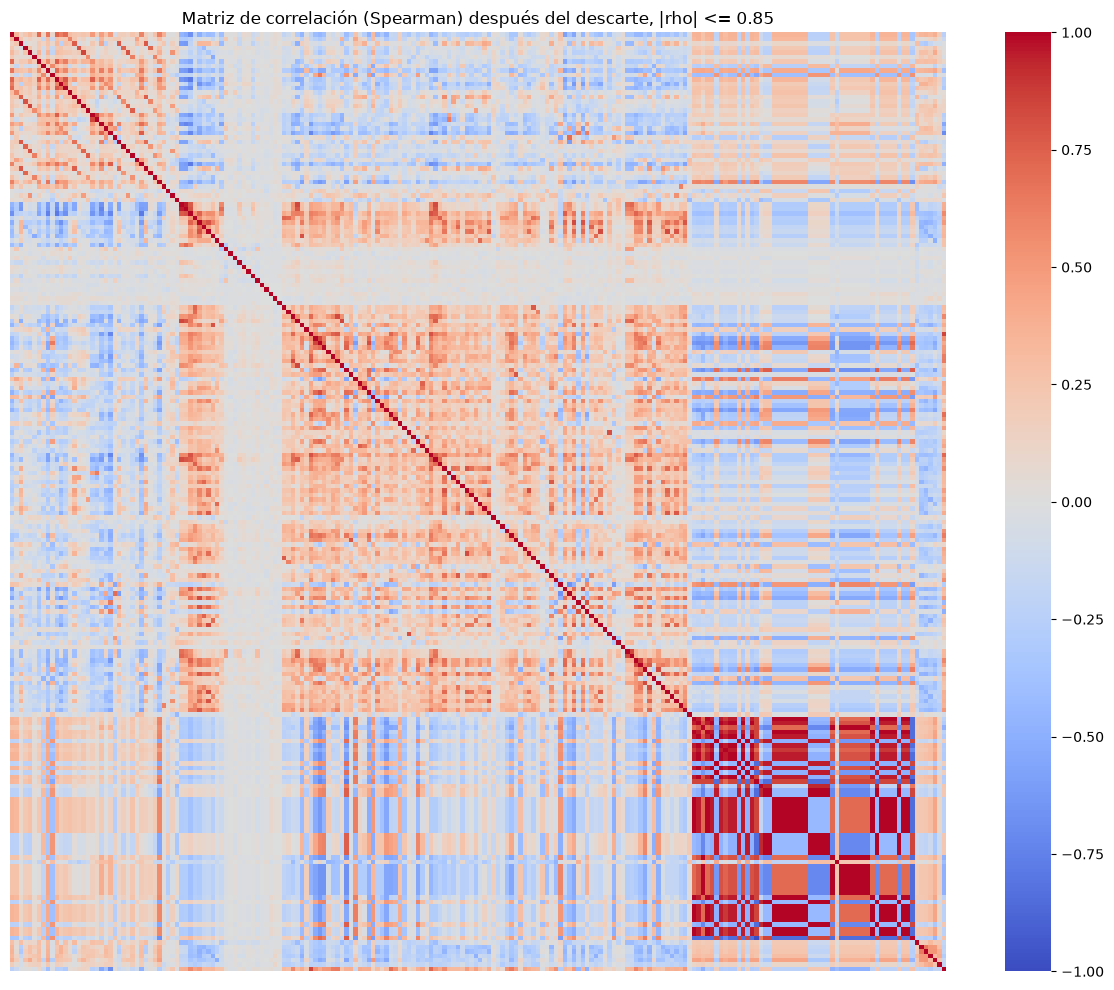

In [83]:
M_nueva = df_corr.corr(method="spearman")
etiquetas = M_nueva.shape[0] <= 40       # con muchas columnas los nombres no se leen

plt.figure(figsize=(12, 10))
sns.heatmap(M_nueva, cmap="coolwarm", vmin=-1, vmax=1, center=0,
            xticklabels=etiquetas, yticklabels=etiquetas)
plt.title(f"Matriz de correlación (Spearman) después del descarte, |rho| <= {UMBRAL_CORRELACION}")
plt.tight_layout()
plt.show()


Consolidado EE | Frio (Kw)                      0.849
Consolidado Agua | Agua Planta (Hl)             0.722
Consolidado KPI | ET Bodega/Hl                 -0.693
Totalizadores Energia | KW Cond 5. 6 y 9        0.690
Totalizadores Agua | Agua Cond REC              0.636
Totalizadores Energia | KW Trafo 10             0.633
Totalizadores Energia | KW Trafo 11             0.632
Consolidado Aire | Aire Producido (M3)          0.590
Consolidado EE | Elaboracion (Kw)               0.585
Consolidado Produccion | Hl Producido Bodega    0.571
Consolidado Agua | Agua Envasado (Hl)           0.564
Totalizadores Energia | KW Cond 11. 12 y 13     0.545
Consolidado KPI | ET Planta / Hl               -0.544
Totalizadores Agua | Temp Tq Intermedio         0.543
Consolidado EE | Pta Agua / Eflu (Kw)           0.539


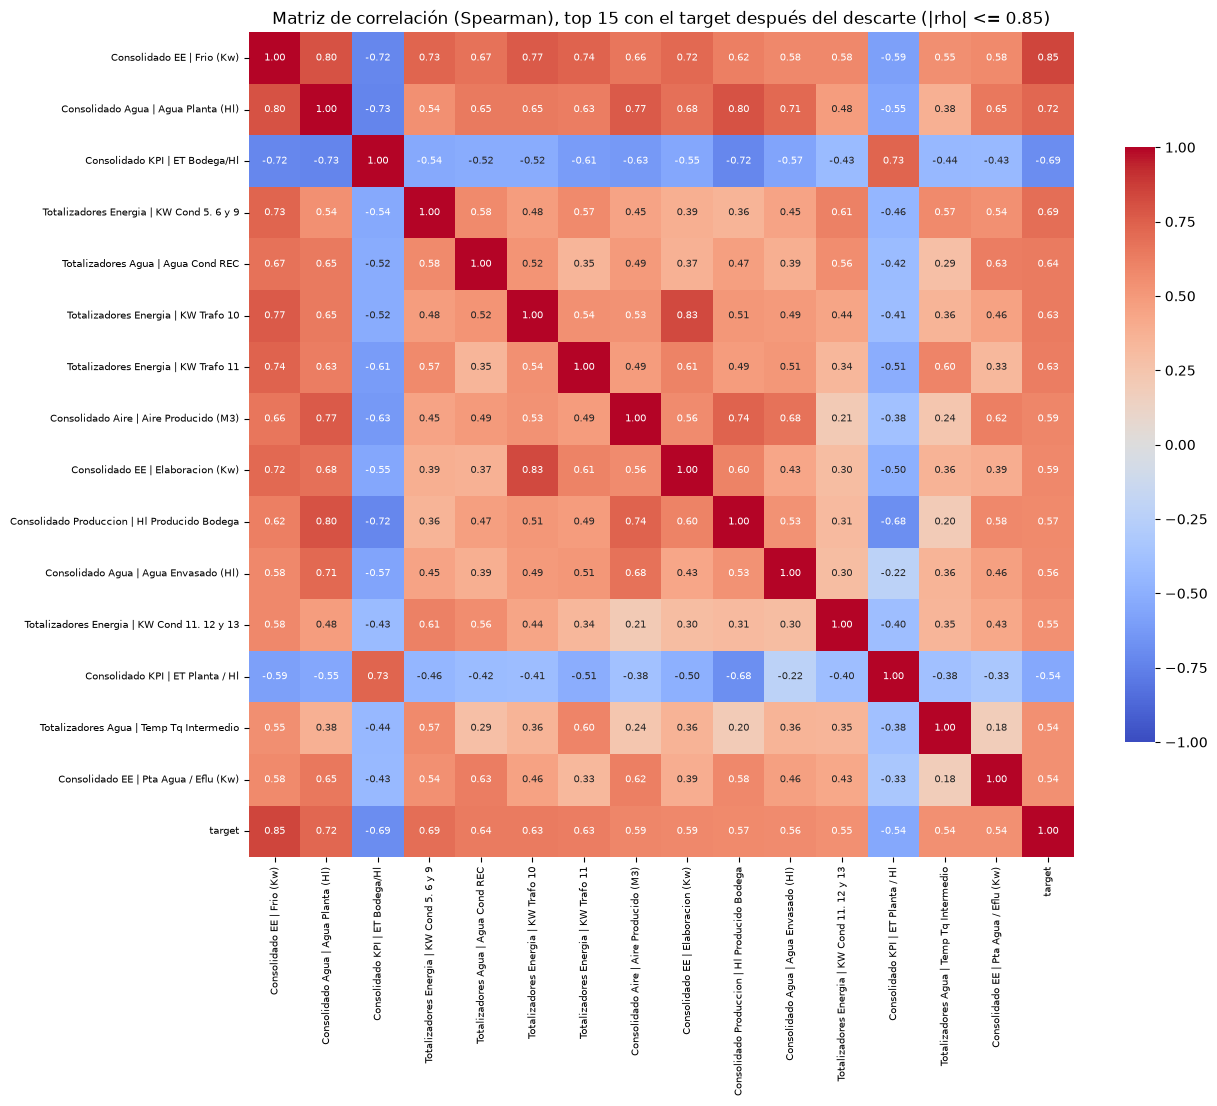

In [84]:
# Top 15 por |correlación| con el target, después del descarte
corr_target = M_nueva["target"].drop("target")
top15 = corr_target.abs().nlargest(15).index
print(corr_target[top15].round(3).to_string())

M15 = M_nueva.loc[[*top15, "target"], [*top15, "target"]]

plt.figure(figsize=(13, 11))
sns.heatmap(M15, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0,
            square=True, annot_kws={"size": 7}, cbar_kws={"shrink": 0.7})
plt.xticks(fontsize=7, rotation=90)
plt.yticks(fontsize=7)
plt.title(f"Matriz de correlación (Spearman), top 15 con el target después del descarte (|rho| <= {UMBRAL_CORRELACION})")
plt.tight_layout()
plt.show()

Siguen habiendo varias del sistema de frío, pero ahora también hay algunas mas intersantes como: 
- Agua planta (Muy correlacionada con frío)
- Bodega (Producción)
- Siguen existiendo los Mycom y Cond 5,6,9. 
- Diferentes transformadores (trafos); puede que un trafo esté vinculado a un aréa y por eso está tan correlacionado, o que esté vinculado al consumo de las maquinas. 


In [85]:
# Registro las columnas eliminadas por correlación para que el pipeline las borre
registrar_borradas(f"correlacion_mayor_{UMBRAL_CORRELACION}", list(borradas))

correlacion_mayor_0.85: 40 columnas registradas en tratamientos_EDA.json


## Visualizaciones
(Serie temporal ya está más arriba)

## Distribución del target

Días excluidos (> 10 × p99): 3
Asimetría: 0.06 | Curtosis (exceso): -0.03


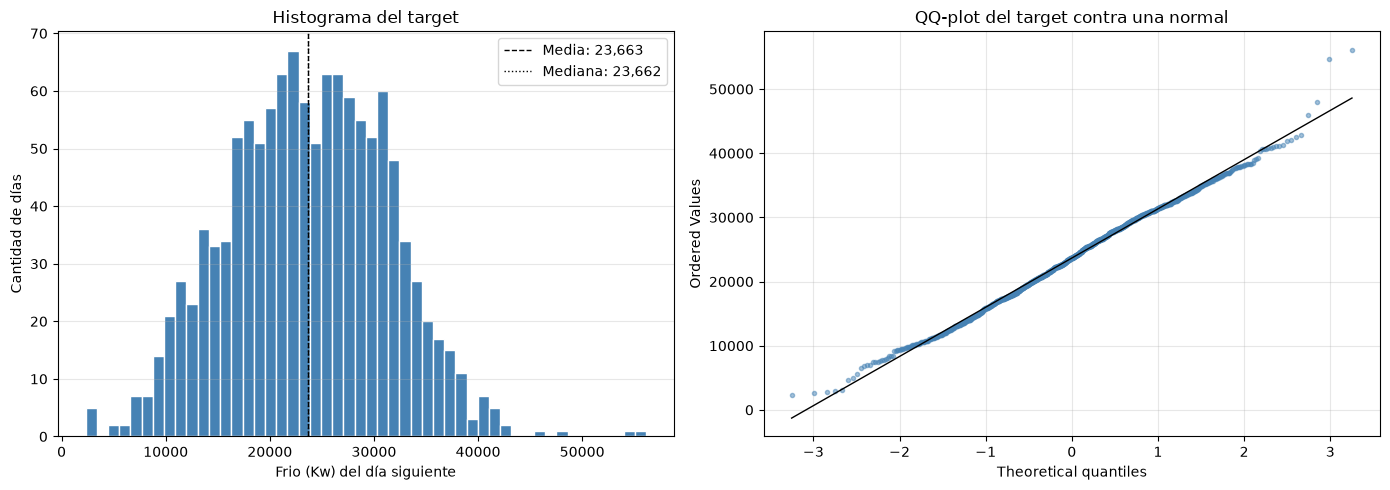

In [86]:
# Distribución del target, sin los días de millones (con ellos el histograma es una sola barra)
y = df_dias["target"]
invalido = y > y.quantile(0.99) * 10
y_valido = y[~invalido]
print(f"Días excluidos (> 10 × p99): {invalido.sum()}")
print(f"Asimetría: {stats.skew(y_valido):.2f} | Curtosis (exceso): {stats.kurtosis(y_valido):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(y_valido, bins=50, color="steelblue", edgecolor="white")
axes[0].axvline(y_valido.mean(), color="black", ls="--", lw=1, label=f"Media: {y_valido.mean():,.0f}")
axes[0].axvline(y_valido.median(), color="black", ls=":", lw=1, label=f"Mediana: {y_valido.median():,.0f}")
axes[0].set_xlabel("Frio (Kw) del día siguiente")
axes[0].set_ylabel("Cantidad de días")
axes[0].set_title("Histograma del target")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

stats.probplot(y_valido, dist="norm", plot=axes[1])
axes[1].get_lines()[0].set(markersize=3, alpha=0.5, color="steelblue")
axes[1].get_lines()[1].set(color="black", lw=1)
axes[1].set_title("QQ-plot del target contra una normal")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Es bimodal? Interesante, quiero ver por que. Voy a clasificar los puntos por estación y ver si es eso lo que la hace bimodal:

           dias    media  mediana  desvio
ESTACION                                 
Invierno    270  15218.0  15478.0  4718.0
Primavera   275  25203.0  24261.0  5144.0
Verano      335  30230.0  30317.0  5980.0
Otoño       330  22623.0  22801.0  5846.0


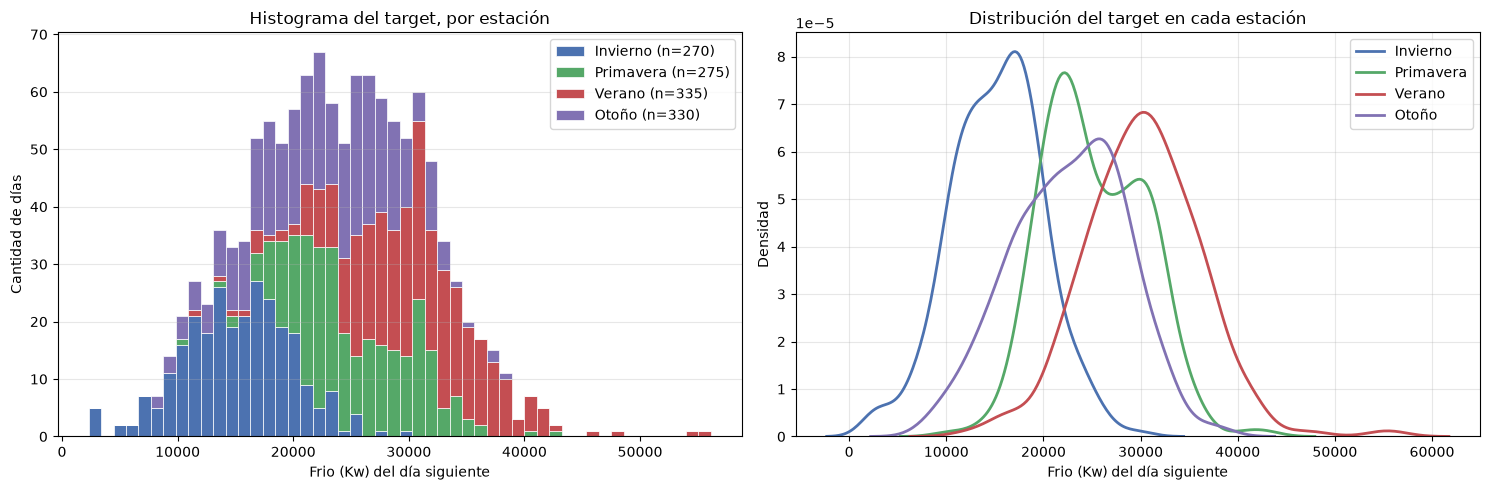

In [87]:
# Target por estación del día que se predice (D+1)
d = df_dias[["DIA", "target"]].copy()
d = d[d["target"] <= d["target"].quantile(0.99) * 10]          # sin los días de millones
# Estaciones meteorológicas, hemisferio norte (mismo criterio que en "Consumo de Frio por estación")
d["ESTACION"] = (d["DIA"] + pd.Timedelta(days=1)).dt.month.map({12: 0, 1: 0, 2: 0, 3: 1, 4: 1, 5: 1,
                                                               6: 2, 7: 2, 8: 2, 9: 3, 10: 3, 11: 3})

nombres = {0: "Invierno", 1: "Primavera", 2: "Verano", 3: "Otoño"}
colores = {0: "#4C72B0", 1: "#55A868", 2: "#C44E52", 3: "#8172B3"}
grupos = [d.loc[d["ESTACION"] == k, "target"] for k in range(4)]
bins = np.histogram_bin_edges(d["target"], bins=50)             # mismos bins que el histograma original

print(d.groupby(d["ESTACION"].map(nombres))["target"]
       .agg(dias="count", media="mean", mediana="median", desvio="std")
       .reindex(nombres.values()).round(0).to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Histograma apilado: la altura total es la misma que la del histograma original
axes[0].hist(grupos, bins=bins, stacked=True, color=[colores[k] for k in range(4)],
             label=[f"{nombres[k]} (n={len(g)})" for k, g in enumerate(grupos)],
             edgecolor="white", linewidth=0.5)
axes[0].set_xlabel("Frio (Kw) del día siguiente")
axes[0].set_ylabel("Cantidad de días")
axes[0].set_title("Histograma del target, por estación")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

# Densidad de cada estación por separado (no apilada)
for k, g in enumerate(grupos):
    sns.kdeplot(g, ax=axes[1], color=colores[k], lw=2, label=nombres[k])
axes[1].set_xlabel("Frio (Kw) del día siguiente")
axes[1].set_ylabel("Densidad")
axes[1].set_title("Distribución del target en cada estación")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Creo que tiene bastante sentido. En verano es el consumo pico de frio, y cuando llega a otoño va bajando poco a poco hasta invierno (pero tarda bastante, sigue consumiendo).

Del otro lado, el invierno es el consumo mínimo y la primavera lo va llevando poco a poco a sus valores de verano.

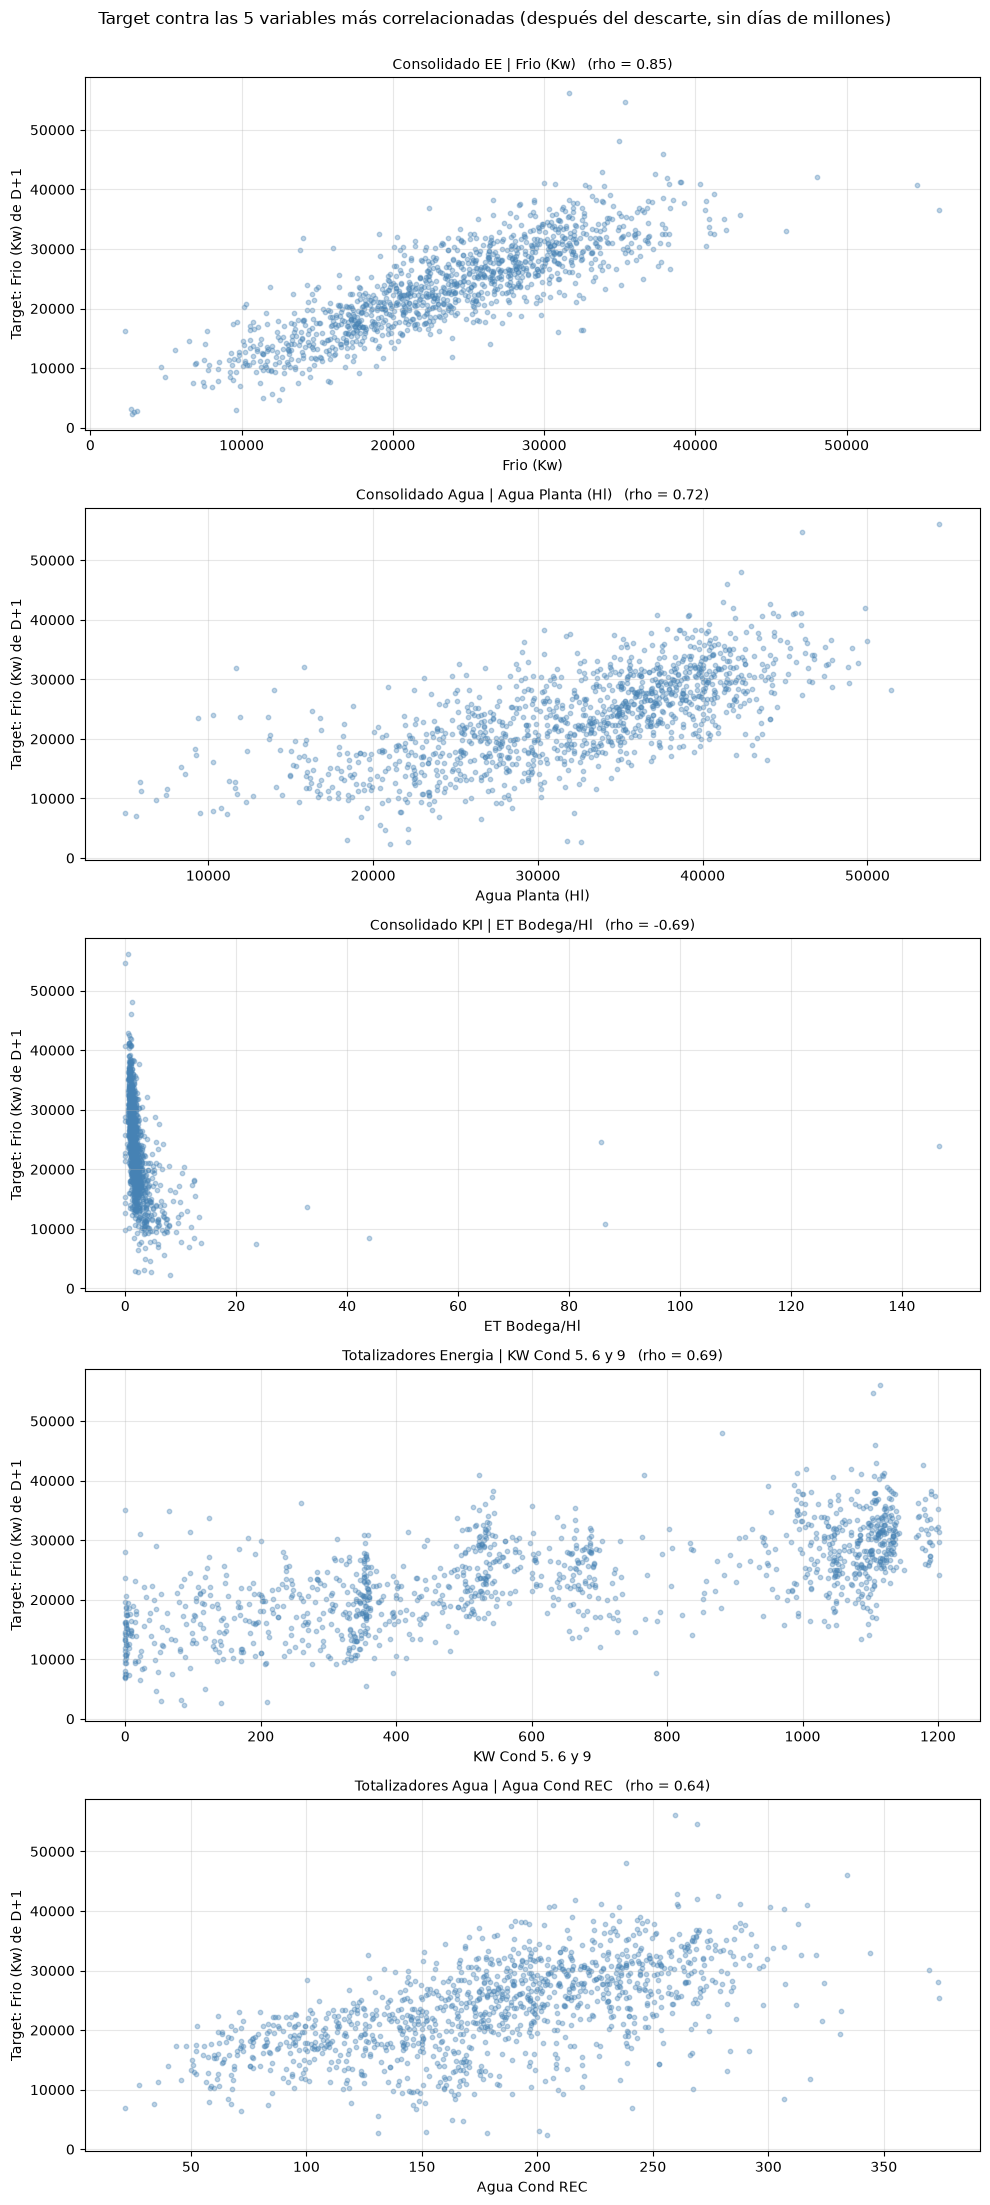

In [88]:
# Las 5 más correlacionadas con el target después del descarte
top5 = M_nueva["target"].drop("target").abs().nlargest(5).index
validos = ((df_corr["target"] <= df_corr["target"].quantile(0.99) * 10)
           & (df_corr[FRIO] <= df_corr[FRIO].quantile(0.99) * 10))
d = df_corr[validos]

fig, axes = plt.subplots(5, 1, figsize=(10, 22))
for ax, c in zip(axes, top5):
    ax.scatter(d[c], d["target"], s=10, alpha=0.35, color="steelblue")
    ax.set_title(f"{c}   (rho = {M_nueva.loc[c, 'target']:.2f})", fontsize=10)
    ax.set_xlabel(c.split(" | ", 1)[-1])
    ax.set_ylabel("Target: Frio (Kw) de D+1")
    ax.grid(alpha=0.3)
fig.suptitle("Target contra las 5 variables más correlacionadas (después del descarte, sin días de millones)", y=1.0)
plt.tight_layout()
plt.show()